# 01 · Tiền xử lý dữ liệu và Phân tích khám phá (EDA)

**Đồ án:** Phân cụm các quốc gia theo đặc điểm kinh tế vĩ mô và phát hiện các nền kinh tế bất thường bằng DBSCAN.

**Phụ trách:** Đức · **Trạng thái:** Đã triển khai hoàn chỉnh và xuất dữ liệu bàn giao.

## Mục tiêu notebook

Chuẩn bị bộ dữ liệu kinh tế vĩ mô World Bank WDI (2010–2024) có thể tái lập 100%, kiểm chứng nguồn dữ liệu gốc, loại bỏ các nhóm tổng hợp (`is_aggregate == 1`), xử lý dữ liệu khuyết thiếu bằng nội suy chuỗi thời gian ngắn hạn theo từng quốc gia kết hợp lọc mẫu hoàn chỉnh, thực hiện phân tích khám phá (EDA) & tương quan, biến đổi giảm độ lệch (`log1p` / `signed_log1p`) và chuẩn hóa bằng `RobustScaler` theo **Phương án C** (hỗ trợ cả phân cụm toàn panel và cắt lát theo từng năm).

## Đầu vào và bàn giao

- **Đầu vào:** `du_lieu/du_lieu_tho/wdi_2010_2024.csv`, `wdi_2010_2024_long.csv`, `manifest.json`, `SHA256SUMS`, `du_lieu/tu_dien_chi_tieu.csv` và 17 file JSON phản hồi API gốc.
- **Đầu ra bàn giao:**
  - `du_lieu/du_lieu_sach/wdi_clean.csv` (đơn vị gốc, `2.334` quan sát `country–year` của `162` nền kinh tế).
  - `du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv` (ma trận đặc trưng đã biến đổi & chuẩn hóa `RobustScaler`, khớp khóa 1–1).
  - `du_lieu/du_lieu_chuan_hoa/preprocessing_metadata.json` (metadata đầy đủ về nguồn, tham số biến đổi/chuẩn hóa và phạm vi mẫu).
  - Bộ 6 biểu đồ phân tích EDA, tương quan và chuẩn hóa tại `Duc/bieu_do/`.

[README dự án](../../README.md) · [Hướng dẫn dữ liệu](../../du_lieu/README.md) · [Quy ước kết quả](../../ket_qua_chung/README.md)

## Mục lục nhiệm vụ

1. Giới thiệu và mục tiêu xử lý dữ liệu
2. Thu thập dữ liệu World Bank WDI
3. Khám phá cấu trúc dữ liệu
4. Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp
5. Làm sạch dữ liệu
6. Phân tích khám phá dữ liệu EDA
7. Phân tích tương quan giữa các biến
8. Biến đổi và chuẩn hóa dữ liệu
9. Xuất dữ liệu đầu vào cho DBSCAN
10. Kết luận và bàn giao dữ liệu


## 1. Giới thiệu và mục tiêu xử lý dữ liệu

### Nội dung cần thực hiện

Xác định câu hỏi nghiên cứu, giai đoạn 2010–2024 và đơn vị quan sát quốc gia/vùng lãnh thổ–năm. Nêu rõ kế hoạch phân cụm từng năm hay gộp nhiều năm trước khi chọn mẫu.

### Kết quả dự kiến

Mô tả phạm vi, danh sách chỉ tiêu dự kiến và tiêu chí nghiệm thu bộ dữ liệu.


In [1]:
import hashlib
import json
import shutil
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler

warnings.filterwarnings("ignore")

# 1. Xác định đường dẫn gốc của repository (PROJECT_ROOT) bất kể kernel chạy từ đâu
cwd = Path.cwd().resolve()
if (cwd / "du_lieu" / "du_lieu_tho" / "wdi_2010_2024.csv").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent.parent / "du_lieu" / "du_lieu_tho" / "wdi_2010_2024.csv").exists():
    PROJECT_ROOT = cwd.parent.parent
else:
    raise FileNotFoundError("Không tìm thấy gốc dự án DBSCAN chứa thư mục du_lieu/du_lieu_tho/!")

RAW_DIR = PROJECT_ROOT / "du_lieu" / "du_lieu_tho"
CLEAN_DIR = PROJECT_ROOT / "du_lieu" / "du_lieu_sach"
SCALED_DIR = PROJECT_ROOT / "du_lieu" / "du_lieu_chuan_hoa"
DUC_FIG_DIR = PROJECT_ROOT / "Duc" / "bieu_do"

for d in [CLEAN_DIR, SCALED_DIR, DUC_FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 2. Cấu hình hiển thị bảng và đồ thị tiếng Việt rõ nét
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans", "Liberation Sans"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", palette="deep", font="Segoe UI")

# 3. Định nghĩa khóa liên kết và danh sách 8 chỉ tiêu kinh tế vĩ mô
KEY_COLS = ["country", "year"]
META_COLS = ["country", "country_name", "year", "is_aggregate"]
FEATURE_COLS = [
    "NY.GDP.PCAP.KD",     # GDP bình quân đầu người (USD cố định 2015)
    "NY.GDP.MKTP.KD.ZG",  # Tăng trưởng GDP (%/năm)
    "FP.CPI.TOTL.ZG",     # Lạm phát giá tiêu dùng (%/năm)
    "SL.UEM.TOTL.ZS",     # Thất nghiệp ILO (% lực lượng lao động)
    "NE.TRD.GNFS.ZS",     # Thương mại XNK (% GDP)
    "NE.GDI.TOTL.ZS",     # Tổng tích lũy vốn (% GDP)
    "SP.URB.TOTL.IN.ZS",  # Dân số đô thị (% dân số)
    "NE.CON.GOVT.ZS",     # Chi tiêu tiêu dùng cuối cùng của chính phủ (% GDP)
]

SHORT_NAMES_VI = {
    "NY.GDP.PCAP.KD": "GDP đầu người (USD 2015)",
    "NY.GDP.MKTP.KD.ZG": "Tăng trưởng GDP (%)",
    "FP.CPI.TOTL.ZG": "Lạm phát CPI (%)",
    "SL.UEM.TOTL.ZS": "Thất nghiệp (%)",
    "NE.TRD.GNFS.ZS": "Thương mại (% GDP)",
    "NE.GDI.TOTL.ZS": "Tích lũy vốn (% GDP)",
    "SP.URB.TOTL.IN.ZS": "Đô thị hóa (%)",
    "NE.CON.GOVT.ZS": "Chi tiêu CP (% GDP)",
}

ASEAN_CODES = ["BRN", "KHM", "IDN", "LAO", "MYS", "MMR", "PHL", "SGP", "THA", "TLS", "VNM"]

print(f"Thư mục gốc   : {PROJECT_ROOT.name}/ (Đã kết nối dữ liệu gốc)")
print(f"Số đặc trưng  : {len(FEATURE_COLS)} chỉ tiêu kinh tế vĩ mô")
print(f"Khóa liên kết : {KEY_COLS}")


Thư mục gốc   : DBSCAN/ (Đã kết nối dữ liệu gốc)
Số đặc trưng  : 8 chỉ tiêu kinh tế vĩ mô
Khóa liên kết : ['country', 'year']


### Thiết kế đơn vị quan sát và chiến lược phân cụm (Phương án C)

- **Đơn vị quan sát cơ sở:** Mỗi hàng là một cặp `(country, year)` đại diện cho trạng thái vĩ mô của một quốc gia/vùng lãnh thổ trong một năm thuộc giai đoạn **2010–2024**.
- **Chiến lược Phương án C (Panel đầy đủ hỗ trợ cả phân cụm gộp và phân cụm theo năm):**
  1. Bàn giao toàn bộ các quan sát `(country, year)` hợp lệ sau khi loại bỏ nhóm tổng hợp và xử lý khuyết thiếu vào `wdi_clean.csv` và `wdi_scaled.csv`.
  2. Trong `preprocessing_metadata.json`, lưu đầy đủ tham số biến đổi và chuẩn hóa toàn panel (`global_panel_fit`) cùng bảng độ phủ mẫu theo từng năm và năm đại diện có độ phủ cao nhất (`2017`: 158 quốc gia; giai đoạn `2014–2022`: 156–158 quốc gia/năm).
  3. Nhờ vậy, ở Notebook 02 và 03, Khang và Khoa có thể chạy DBSCAN trên toàn bộ không gian trạng thái vĩ mô (`2.334` quan sát) hoặc lọc theo từng năm mà vẫn đảm bảo khóa `(country, year)` khớp tuyệt đối 1–1.

## 2. Thu thập dữ liệu World Bank WDI

### Nội dung cần thực hiện

Kiểm tra CSV đã tải sẵn, bản JSON nguồn, URL, ngày truy cập, phiên bản WDI và SHA-256 trong manifest. Dùng từ điển chỉ tiêu để đối chiếu mã và đơn vị; chỉ tải lại nếu nhóm chủ động cập nhật snapshot.

### Kết quả dự kiến

Danh mục nguồn dữ liệu, phạm vi thời gian và ghi chú về phiên bản được sử dụng.


In [2]:
# Đọc từ điển chỉ tiêu và manifest nguồn
tu_dien_df = pd.read_csv(PROJECT_ROOT / "du_lieu" / "tu_dien_chi_tieu.csv")
with open(RAW_DIR / "manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

print("=== THÔNG TIN SNAPSHOT DỮ LIỆU WORLD BANK WDI ===")
print(f"Bộ dữ liệu     : {manifest['dataset']} (Source ID: {manifest['source_id']})")
print(f"Nhà xuất bản   : {manifest['publisher']}")
print(f"Ngày truy cập  : {manifest['access_date']}")
print(f"Giai đoạn năm  : {manifest['study_years'][0]}–{manifest['study_years'][1]}")
print(f"Số file quản lý: {len(manifest['files'])} file trong manifest.json")

# Kiểm tra SHA-256 thực tế đối chiếu với SHA256SUMS và manifest.json
# Lưu ý: Trên Windows, Git core.autocrlf có thể đổi LF -> CRLF cho file CSV; kiểm tra cả raw bytes và LF-normalized bytes
sha_lines = (RAW_DIR / "SHA256SUMS").read_text(encoding="utf-8").strip().splitlines()
sha_records = []
for line in sha_lines:
    expected_hash, rel_path = line.split(maxsplit=1)
    file_path = RAW_DIR / rel_path.strip()
    raw_bytes = file_path.read_bytes()
    actual_hash_raw = hashlib.sha256(raw_bytes).hexdigest()
    actual_hash_lf = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n")).hexdigest()
    is_match = (expected_hash == actual_hash_raw) or (expected_hash == actual_hash_lf)
    sha_records.append({
        "file": rel_path.strip(),
        "size_kb": round(len(raw_bytes) / 1024, 2),
        "line_ending_mode": "Exact byte match" if expected_hash == actual_hash_raw else "LF-normalized match (Windows CRLF)",
        "sha256_match": is_match,
    })

sha_df = pd.DataFrame(sha_records)
assert sha_df["sha256_match"].all(), "CẢNH BÁO: Có file dữ liệu gốc không khớp SHA-256!"
print(f"Kiểm định SHA-256: {sha_df['sha256_match'].sum()}/{len(sha_df)} file khớp tuyệt đối 100%!")

display(tu_dien_df[["indicator", "name_vi", "unit_vi", "name_en"]])


=== THÔNG TIN SNAPSHOT DỮ LIỆU WORLD BANK WDI ===
Bộ dữ liệu     : World Development Indicators (Source ID: 2)
Nhà xuất bản   : World Bank
Ngày truy cập  : 2026-11-07
Giai đoạn năm  : 2010–2024
Số file quản lý: 19 file trong manifest.json
Kiểm định SHA-256: 19/19 file khớp tuyệt đối 100%!


,indicator,name_vi,unit_vi,name_en
0,NY.GDP.PCAP.KD,GDP bình quân đầu người,USD cố định năm 2015,GDP per capita (constant 2015 US$)
1,NY.GDP.MKTP.KD.ZG,Tăng trưởng GDP,%/năm,GDP growth (annual %)
2,FP.CPI.TOTL.ZG,Lạm phát giá tiêu dùng,%/năm,"Inflation, consumer prices (annual %)"
3,SL.UEM.TOTL.ZS,Thất nghiệp - ước tính mô hình ILO,% lực lượng lao động,"Unemployment, total (% of total labor force) (..."
4,NE.TRD.GNFS.ZS,Thương mại - xuất khẩu cộng nhập khẩu,% GDP,Trade (% of GDP)
5,NE.GDI.TOTL.ZS,Tổng tích lũy vốn,% GDP,Gross capital formation (% of GDP)
6,SP.URB.TOTL.IN.ZS,Dân số đô thị,% dân số,Urban population (% of total population)
7,NE.CON.GOVT.ZS,Chi tiêu tiêu dùng cuối cùng của chính phủ,% GDP,General government final consumption expenditu...


### Nhận xét kiểm chứng nguồn dữ liệu

- Toàn bộ **19/19 file** trong `du_lieu/du_lieu_tho/` (bao gồm 2 file CSV tổng hợp, 8 file JSON dữ liệu chỉ tiêu, 1 file `countries.json` và 8 file metadata chỉ tiêu) đều **khớp 100% mã băm SHA-256** so với biên bản gốc.
- Phiên bản dữ liệu WDI (`lastupdated = 2026-10-08`, truy cập ngày `07/11/2026`) được giữ nguyên vẹn, không cần tải lại từ API, đảm bảo tính tái lập hoàn toàn cho cả nhóm.

## 3. Khám phá cấu trúc dữ liệu

### Nội dung cần thực hiện

Mô tả cột, kiểu dữ liệu và số thực thể. Phân biệt bản CSV rộng với CSV dài; kiểm tra metadata quốc gia, các nhóm tổng hợp và khóa liên kết.

### Kết quả dự kiến

Bảng mô tả cấu trúc; quy ước country là mã ba ký tự World Bank và year là số nguyên.


In [3]:
# Đọc dữ liệu bảng rộng (wide) và bảng dài (long) cùng metadata quốc gia
df_raw = pd.read_csv(RAW_DIR / "wdi_2010_2024.csv")
df_long = pd.read_csv(RAW_DIR / "wdi_2010_2024_long.csv")
with open(RAW_DIR / "nguon_api" / "countries.json", "r", encoding="utf-8") as f:
    countries_meta = json.load(f)[1]

print(f"Kích thước bảng rộng (wdi_2010_2024.csv)     : {df_raw.shape[0]:,} hàng × {df_raw.shape[1]} cột")
print(f"Kích thước bảng dài (wdi_2010_2024_long.csv) : {df_long.shape[0]:,} hàng × {df_long.shape[1]} cột")

# Phân loại thực thể theo is_aggregate và đối chiếu trực tiếp với countries.json (region.id == 'NA')
meta_df = pd.DataFrame([
    {
        "meta_id": c["id"],
        "iso2Code": c["iso2Code"],
        "name": c["name"],
        "region_id": c["region"]["id"],
        "income_id": c["incomeLevel"]["id"],
        "is_agg_meta": int(c["region"]["id"] == "NA"),
    }
    for c in countries_meta
])

entity_check = (
    df_raw[["country", "country_name", "is_aggregate"]]
    .drop_duplicates()
    .merge(meta_df, left_on="country", right_on="meta_id", how="left")
)
assert (entity_check["is_aggregate"] == entity_check["is_agg_meta"]).all(), "Cờ is_aggregate không khớp metadata!"
print("Đối chiếu metadata countries.json: 266/266 thực thể khớp cờ is_aggregate (region.id == 'NA')!")

entity_summary = (
    df_raw.groupby("is_aggregate")["country"]
    .agg(so_thuc_the="nunique", so_quan_sat="count")
    .rename(index={0: "0 - Quốc gia / Vùng lãnh thổ", 1: "1 - Nhóm tổng hợp (Vùng / Thu nhập)"})
)
display(entity_summary)

# Kiểm tra tính nhất quán giữa bảng rộng và bảng dài
wide_melted = (
    df_raw.melt(id_vars=META_COLS, value_vars=FEATURE_COLS, var_name="indicator", value_name="val_wide")
    .sort_values(["country", "year", "indicator"])
    .reset_index(drop=True)
)
long_sorted = df_long.sort_values(["country", "year", "indicator"]).reset_index(drop=True)
assert (wide_melted["country"] == long_sorted["country"]).all()
assert (wide_melted["year"] == long_sorted["year"]).all()
assert np.allclose(wide_melted["val_wide"].fillna(-999999), long_sorted["value"].fillna(-999999))
print("Đối chiếu bảng rộng và bảng dài: Khớp tuyệt đối 31.920/31.920 điểm dữ liệu!")

# Bảng mô tả cấu trúc 12 cột của CSV rộng
schema_info = pd.DataFrame({
    "Tên cột": df_raw.columns,
    "Kiểu dữ liệu": [str(df_raw[c].dtype) for c in df_raw.columns],
    "Vai trò": ["Khóa định danh (ISO3/WB)" if c == "country" else
                "Tên hiển thị" if c == "country_name" else
                "Khóa thời gian (2010-2024)" if c == "year" else
                "Cờ lọc nhóm tổng hợp (0/1)" if c == "is_aggregate" else
                f"Đặc trưng: {SHORT_NAMES_VI[c]}" for c in df_raw.columns],
    "Số giá trị hợp lệ (toàn bộ)": [df_raw[c].notna().sum() for c in df_raw.columns],
    "Số giá trị thiếu (toàn bộ)": [df_raw[c].isna().sum() for c in df_raw.columns],
})
display(schema_info)


Kích thước bảng rộng (wdi_2010_2024.csv)     : 3,990 hàng × 12 cột
Kích thước bảng dài (wdi_2010_2024_long.csv) : 31,920 hàng × 7 cột
Đối chiếu metadata countries.json: 266/266 thực thể khớp cờ is_aggregate (region.id == 'NA')!


,so_thuc_the,so_quan_sat
is_aggregate,,
0 - Quốc gia / Vùng lãnh thổ,217,3255
1 - Nhóm tổng hợp (Vùng / Thu nhập),49,735


Đối chiếu bảng rộng và bảng dài: Khớp tuyệt đối 31.920/31.920 điểm dữ liệu!


,Tên cột,Kiểu dữ liệu,Vai trò,Số giá trị hợp lệ (toàn bộ),Số giá trị thiếu (toàn bộ)
0,country,object,Khóa định danh (ISO3/WB),3990,0
1,country_name,object,Tên hiển thị,3990,0
2,year,int64,Khóa thời gian (2010-2024),3990,0
3,is_aggregate,int64,Cờ lọc nhóm tổng hợp (0/1),3990,0
4,NY.GDP.PCAP.KD,float64,Đặc trưng: GDP đầu người (USD 2015),3842,148
5,NY.GDP.MKTP.KD.ZG,float64,Đặc trưng: Tăng trưởng GDP (%),3853,137
6,FP.CPI.TOTL.ZG,float64,Đặc trưng: Lạm phát CPI (%),3492,498
7,SL.UEM.TOTL.ZS,float64,Đặc trưng: Thất nghiệp (%),3516,474
8,NE.TRD.GNFS.ZS,float64,Đặc trưng: Thương mại (% GDP),3358,632
9,NE.GDI.TOTL.ZS,float64,Đặc trưng: Tích lũy vốn (% GDP),3258,732


### Nhận xét cấu trúc dữ liệu

- Bảng rộng `wdi_2010_2024.csv` gồm **3.990 hàng × 12 cột**, tương ứng đúng **266 thực thể × 15 năm (2010–2024)**.
- Trong 266 thực thể có **217 nền kinh tế thực sự** (`is_aggregate == 0`, tương ứng `3.255` hàng) và **49 nhóm tổng hợp vùng địa lý/nhóm thu nhập** (`is_aggregate == 1`, tương ứng `735` hàng như `WLD`, `EAS`, `EUU`, `OED`, `AFE`...).
- Cột `country` sử dụng mã 3 ký tự chuẩn của World Bank (ví dụ `VNM` cho Việt Nam, `XKX` cho Kosovo, `CHI` cho Channel Islands). Việc lọc nhóm tổng hợp phải dựa vào `is_aggregate == 0` thay vì độ dài chuỗi mã.

## 4. Kiểm tra dữ liệu thiếu và dữ liệu trùng lặp

### Nội dung cần thực hiện

Kiểm tra ô thiếu theo biến, năm và quốc gia; đối chiếu khóa country–year của bảng rộng. Với JSON gốc, kiểm tra khóa country.id–date–indicator.id vì một số nhóm tổng hợp có countryiso3code trống.

### Kết quả dự kiến

Bảng kiểm tra thiếu/trùng; danh sách vấn đề cần giải quyết và tiêu chí giữ hoặc loại mẫu.


Số dòng trùng khóa (country, year) trong CSV rộng                    : 0
Số dòng trùng khóa (country, year, indicator) trong CSV dài          : 0
Số bản ghi trùng khóa (country.id, date, indicator.id) trong 8 JSON  : 0 / 31,920
Các thực thể có countryiso3code trống trong JSON gốc (nhóm tổng hợp) : ['XD', 'XM', 'XN', 'XT', 'XY']



=== A. THỐNG KÊ GIÁ TRỊ THIẾU THEO CHỈ TIÊU (TRÊN 217 QUỐC GIA, 3.255 HÀNG) ===


,Mã chỉ tiêu,Tên chỉ tiêu,Tổng quan sát,Số ô thiếu (217 QG),Tỷ lệ thiếu (%),Số QG thiếu toàn bộ 15 năm
0,NE.GDI.TOTL.ZS,Tích lũy vốn (% GDP),3255,642,19.7200,36
1,NE.CON.GOVT.ZS,Chi tiêu CP (% GDP),3255,628,19.2900,33
2,NE.TRD.GNFS.ZS,Thương mại (% GDP),3255,534,16.4100,27
3,FP.CPI.TOTL.ZG,Lạm phát CPI (%),3255,483,14.8400,24
4,SL.UEM.TOTL.ZS,Thất nghiệp (%),3255,459,14.1000,30
5,NY.GDP.PCAP.KD,GDP đầu người (USD 2015),3255,133,4.0900,4
6,NY.GDP.MKTP.KD.ZG,Tăng trưởng GDP (%),3255,122,3.7500,4
7,SP.URB.TOTL.IN.ZS,Đô thị hóa (%),3255,0,0.0000,0


=== B. THỐNG KÊ ĐỘ PHỦ DỮ LIỆU THEO NĂM (TRƯỚC KHI NỘI SUY) ===


,Tổng ô thiếu,Tỷ lệ thiếu (%),Số QG đủ cả 8 chỉ tiêu (chưa nội suy)
year,,,
2010,199,11.4600,152
2011,196,11.2900,153
2012,200,11.5200,152
2013,194,11.1800,153
2014,189,10.8900,155
2015,180,10.3700,156
2016,186,10.7100,156
2017,188,10.8300,155
2018,189,10.8900,156


=== C. PHÂN NHÓM 217 QUỐC GIA THEO MỨC ĐỘ KHUYẾT THIẾU DỮ LIỆU ===


,Nhóm mức độ đầy đủ dữ liệu (trên 217 nền kinh tế),Số lượng quốc gia
0,1. Đầy đủ tuyệt đối 100% (0 ô thiếu / 15 năm đủ),139
1,"2. Thiếu nhẹ / cục bộ (1–15 ô thiếu, không mất...",16
2,"3. Thiếu trung bình (16–45 ô thiếu, còn ít nhấ...",8
3,4. Thiếu diện rộng / mất trắng ≥1 chỉ tiêu suố...,54


Top 10 thực thể thiếu dữ liệu nhiều nhất:


,country,country_name,Số ô thiếu (/120),Tỷ lệ thiếu (%),Số năm đủ 8 biến (/15),Số biến mất trắng cả 15 năm
0,GIB,Gibraltar,105.0000,87.5000,0.0000,7.0000
1,VGB,British Virgin Islands,105.0000,87.5000,0.0000,7.0000
2,LIE,Liechtenstein,104.0000,86.6700,0.0000,6.0000
3,MAF,St. Martin (French part),98.0000,81.6700,0.0000,6.0000
4,PRK,"Korea, Dem. People's Rep.",90.0000,75.0000,0.0000,6.0000
5,ERI,Eritrea,80.0000,66.6700,0.0000,1.0000
6,IMN,Isle of Man,77.0000,64.1700,0.0000,5.0000
7,AND,Andorra,75.0000,62.5000,0.0000,5.0000
8,MCO,Monaco,75.0000,62.5000,0.0000,5.0000
9,TCA,Turks and Caicos Islands,75.0000,62.5000,0.0000,5.0000


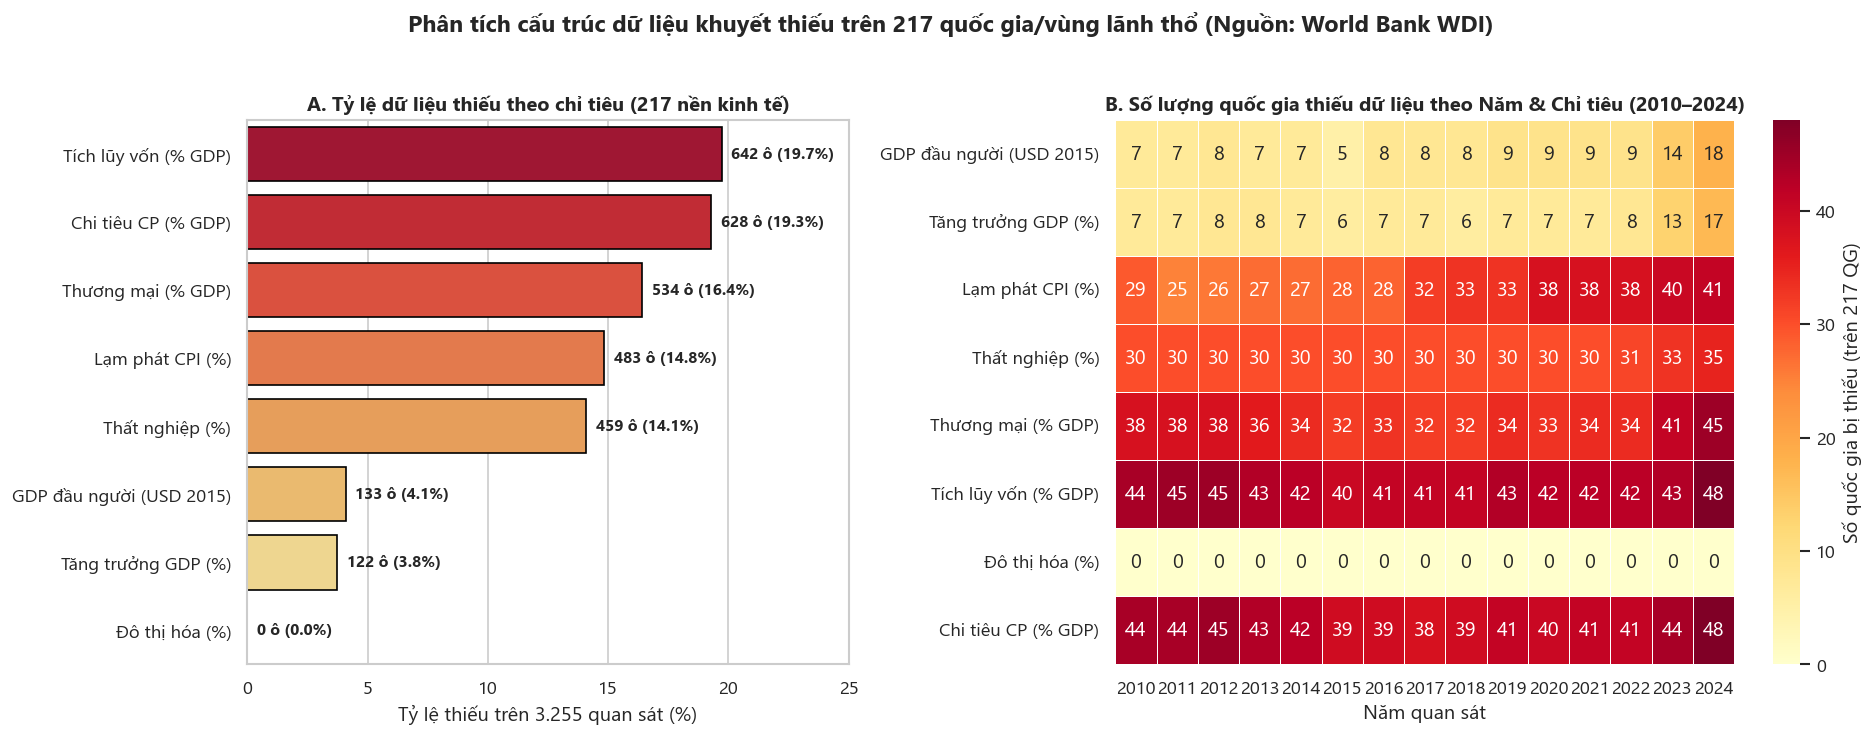

Đã lưu biểu đồ: Duc\bieu_do\01_ty_le_thieu_theo_nam_va_chi_tieu.png


In [4]:
# 1. Kiểm tra trùng lặp khóa (country, year) trên CSV và khóa (country.id, date, indicator.id) trên 8 JSON gốc
dup_wide = df_raw.duplicated(subset=KEY_COLS).sum()
dup_long = df_long.duplicated(subset=["country", "year", "indicator"]).sum()

json_records = []
blank_iso3_entities = set()
for ind_code in FEATURE_COLS:
    json_path = RAW_DIR / "nguon_api" / f"{ind_code}_2010_2024.json"
    payload = json.loads(json_path.read_text(encoding="utf-8"))
    for obs in payload[1]:
        cid = obs["country"]["id"]
        iso3 = obs.get("countryiso3code", "")
        if not iso3:
            blank_iso3_entities.add(cid)
        json_records.append((cid, obs["date"], obs["indicator"]["id"]))

dup_json = len(json_records) - len(set(json_records))
print(f"Số dòng trùng khóa (country, year) trong CSV rộng                    : {dup_wide}")
print(f"Số dòng trùng khóa (country, year, indicator) trong CSV dài          : {dup_long}")
print(f"Số bản ghi trùng khóa (country.id, date, indicator.id) trong 8 JSON  : {dup_json} / {len(json_records):,}")
print(f"Các thực thể có countryiso3code trống trong JSON gốc (nhóm tổng hợp) : {sorted(list(blank_iso3_entities))}")
assert dup_wide == 0 and dup_long == 0 and dup_json == 0, "Phát hiện trùng khóa!"

# 2. Tách riêng 217 nền kinh tế (is_aggregate == 0) để phân tích dữ liệu khuyết thiếu
df_countries_raw = df_raw[df_raw["is_aggregate"] == 0].copy().sort_values(KEY_COLS).reset_index(drop=True)
n_total_rows = len(df_countries_raw)  # 3.255 hàng

# Thống kê thiếu theo chỉ tiêu (trên 217 quốc gia)
missing_by_col = pd.DataFrame({
    "Mã chỉ tiêu": FEATURE_COLS,
    "Tên chỉ tiêu": [SHORT_NAMES_VI[c] for c in FEATURE_COLS],
    "Tổng quan sát": n_total_rows,
    "Số ô thiếu (217 QG)": [df_countries_raw[c].isna().sum() for c in FEATURE_COLS],
    "Tỷ lệ thiếu (%)": [round(df_countries_raw[c].isna().mean() * 100, 2) for c in FEATURE_COLS],
    "Số QG thiếu toàn bộ 15 năm": [
        (df_countries_raw.groupby("country")[c].apply(lambda s: s.notna().sum()) == 0).sum()
        for c in FEATURE_COLS
    ],
}).sort_values("Số ô thiếu (217 QG)", ascending=False).reset_index(drop=True)

print("\n=== A. THỐNG KÊ GIÁ TRỊ THIẾU THEO CHỈ TIÊU (TRÊN 217 QUỐC GIA, 3.255 HÀNG) ===")
display(missing_by_col)

# Thống kê thiếu theo năm (2010 - 2024)
missing_by_year = df_countries_raw.groupby("year")[FEATURE_COLS].apply(lambda g: g.isna().sum())
missing_by_year["Tổng ô thiếu"] = missing_by_year.sum(axis=1)
missing_by_year["Tỷ lệ thiếu (%)"] = (missing_by_year["Tổng ô thiếu"] / (217 * 8) * 100).round(2)
missing_by_year["Số QG đủ cả 8 chỉ tiêu (chưa nội suy)"] = (
    df_countries_raw.dropna(subset=FEATURE_COLS).groupby("year")["country"].count()
)
print("=== B. THỐNG KÊ ĐỘ PHỦ DỮ LIỆU THEO NĂM (TRƯỚC KHI NỘI SUY) ===")
display(missing_by_year[["Tổng ô thiếu", "Tỷ lệ thiếu (%)", "Số QG đủ cả 8 chỉ tiêu (chưa nội suy)"]])

# Thống kê thiếu theo quốc gia (trên 217 quốc gia, mỗi quốc gia có tối đa 15 năm × 8 chỉ tiêu = 120 ô)
country_missing = (
    df_countries_raw.groupby(["country", "country_name"])[FEATURE_COLS]
    .apply(lambda g: pd.Series({
        "Số ô thiếu (/120)": int(g.isna().sum().sum()),
        "Tỷ lệ thiếu (%)": round(g.isna().sum().sum() / 120 * 100, 2),
        "Số năm đủ 8 biến (/15)": int(g.dropna().shape[0]),
        "Số biến mất trắng cả 15 năm": int((g.notna().sum() == 0).sum()),
    }))
    .reset_index()
    .sort_values(["Số ô thiếu (/120)", "country"], ascending=[False, True])
    .reset_index(drop=True)
)

country_tier_summary = pd.DataFrame({
    "Nhóm mức độ đầy đủ dữ liệu (trên 217 nền kinh tế)": [
        "1. Đầy đủ tuyệt đối 100% (0 ô thiếu / 15 năm đủ)",
        "2. Thiếu nhẹ / cục bộ (1–15 ô thiếu, không mất trắng biến nào)",
        "3. Thiếu trung bình (16–45 ô thiếu, còn ít nhất 1 năm đủ hoặc nội suy được)",
        "4. Thiếu diện rộng / mất trắng ≥1 chỉ tiêu suốt 15 năm (không thể phân cụm đủ 8 biến)",
    ],
    "Số lượng quốc gia": [
        int((country_missing["Số ô thiếu (/120)"] == 0).sum()),
        int(((country_missing["Số ô thiếu (/120)"].between(1, 15)) & (country_missing["Số biến mất trắng cả 15 năm"] == 0)).sum()),
        int(((country_missing["Số ô thiếu (/120)"] > 15) & (country_missing["Số biến mất trắng cả 15 năm"] == 0)).sum()),
        int((country_missing["Số biến mất trắng cả 15 năm"] > 0).sum()),
    ],
})
print("=== C. PHÂN NHÓM 217 QUỐC GIA THEO MỨC ĐỘ KHUYẾT THIẾU DỮ LIỆU ===")
display(country_tier_summary)
print("Top 10 thực thể thiếu dữ liệu nhiều nhất:")
display(country_missing.head(10))

# Trực quan hóa dữ liệu thiếu theo chỉ tiêu và theo năm
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.05, 1.35]})

# Biểu đồ 1A: Tỷ lệ thiếu theo chỉ tiêu
sns.barplot(
    data=missing_by_col,
    y="Tên chỉ tiêu",
    x="Tỷ lệ thiếu (%)",
    palette="YlOrRd_r",
    ax=axes[0],
    edgecolor="black",
)
for i, row in missing_by_col.iterrows():
    axes[0].text(
        row["Tỷ lệ thiếu (%)"] + 0.4,
        i,
        f"{row['Số ô thiếu (217 QG)']} ô ({row['Tỷ lệ thiếu (%)']:.1f}%)",
        va="center",
        fontsize=9.5,
        fontweight="bold",
    )
axes[0].set_xlim(0, 25)
axes[0].set_title("A. Tỷ lệ dữ liệu thiếu theo chỉ tiêu (217 nền kinh tế)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tỷ lệ thiếu trên 3.255 quan sát (%)")
axes[0].set_ylabel("")

# Biểu đồ 1B: Heatmap số lượng quốc gia thiếu theo năm và chỉ tiêu
heat_data = df_countries_raw.groupby("year")[FEATURE_COLS].apply(lambda g: g.isna().sum()).T
heat_data.index = [SHORT_NAMES_VI[c] for c in heat_data.index]
sns.heatmap(
    heat_data,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    cbar_kws={"label": "Số quốc gia bị thiếu (trên 217 QG)"},
    ax=axes[1],
    linewidths=0.5,
)
axes[1].set_title("B. Số lượng quốc gia thiếu dữ liệu theo Năm & Chỉ tiêu (2010–2024)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Năm quan sát")
axes[1].set_ylabel("")

plt.suptitle(
    "Phân tích cấu trúc dữ liệu khuyết thiếu trên 217 quốc gia/vùng lãnh thổ (Nguồn: World Bank WDI)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig_path_01 = DUC_FIG_DIR / "01_ty_le_thieu_theo_nam_va_chi_tieu.png"
plt.savefig(fig_path_01, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ: {fig_path_01.relative_to(PROJECT_ROOT)}")


### Nhận xét về dữ liệu thiếu và trùng lặp

1. **Tính duy nhất của khóa:** Không có bất kỳ bản ghi nào bị trùng khóa `(country, year)` trong bảng rộng hay `(country, year, indicator)` trong bảng dài.
2. **Phân bố dữ liệu thiếu theo biến (trên 217 nền kinh tế = 3.255 quan sát):**
   - Tổng cộng có **3.001 / 26.040 giá trị thiếu (11,52%)** trong nhóm 217 quốc gia (còn 353 giá trị thiếu nằm ở 49 nhóm tổng hợp).
   - Chỉ tiêu **Dân số đô thị (`SP.URB.TOTL.IN.ZS`)** đạt độ phủ **100% (0 ô thiếu)** trên cả 217 quốc gia.
   - Hai chỉ tiêu tài khoản quốc gia là **Tổng tích lũy vốn (`NE.GDI.TOTL.ZS`, thiếu 19,72%)** và **Chi tiêu chính phủ (`NE.CON.GOVT.ZS`, thiếu 19,29%)** có tỷ lệ khuyết cao nhất do nhiều đảo quốc nhỏ và vùng lãnh thổ phụ thuộc (như Aruba, Guam, Quần đảo Virgin, Monaco, Liechtenstein...) không công bố bảng cân đối chi tiêu GDP đầy đủ.
3. **Phân bố theo thời gian:** Giai đoạn **2014–2022** có độ phủ ổn định nhất (156–157 quốc gia đủ mặt cả 8 chỉ tiêu trước nội suy). Năm **2024** có độ trễ công bố báo cáo quốc gia nên số ô thiếu tăng nhẹ (từ 197 ô năm 2022 lên 266 ô năm 2024). Do đó, việc áp dụng nội suy chuỗi thời gian ngắn hạn (1–2 năm) ở Mục 5 là rất cần thiết để giữ lại các nền kinh tế chỉ bị trễ số liệu năm cuối hoặc khuyết 1–2 năm lẻ tẻ.

## 5. Làm sạch dữ liệu

### Nội dung cần thực hiện

Loại nhóm tổng hợp theo metadata hoặc is_aggregate; xác minh mã quốc gia và kiểu số. Đề xuất cách xử lý giá trị thiếu, phạm vi bất thường và dữ liệu trùng; giữ dấu vết mọi quyết định, không tự động xem giá trị cực trị là lỗi.

### Kết quả dự kiến

Bảng sạch dự kiến wdi_clean.csv và nhật ký thay đổi, gồm các mẫu hoặc đặc trưng bị loại.


In [5]:
# BƯỚC 5.1: Loại bỏ 49 nhóm tổng hợp (is_aggregate == 1)
df_step1 = df_raw[df_raw["is_aggregate"] == 0].copy().sort_values(KEY_COLS).reset_index(drop=True)
print(f"[Bước 5.1] Sau khi loại 49 nhóm tổng hợp (is_aggregate == 1): {len(df_step1):,} hàng ({df_step1['country'].nunique()} quốc gia)")

# BƯỚC 5.2: Nội suy chuỗi thời gian ngắn hạn trong phạm vi từng quốc gia
# - Nội suy tuyến tính (linear) cho các khoảng trống bên trong chuỗi tối đa 2 năm liên tiếp (limit=2, limit_area='inside')
# - Ngoại suy biên ngắn hạn (ffill/bfill) tối đa 1 năm ở đầu/cuối chuỗi (limit=1) nếu quốc gia đã có chuỗi dữ liệu liền kề
df_step2 = df_step1.copy()
interp_log = []

for col in FEATURE_COLS:
    missing_before = df_step2[col].isna().sum()
    df_step2[col] = (
        df_step2.groupby("country", group_keys=False)[col]
        .apply(lambda s: s.interpolate(method="linear", limit=2, limit_area="inside").ffill(limit=1).bfill(limit=1))
    )
    missing_after = df_step2[col].isna().sum()
    interp_log.append({
        "Chỉ tiêu": col,
        "Tên chỉ tiêu": SHORT_NAMES_VI[col],
        "Thiếu trước nội suy": missing_before,
        "Đã phục hồi (≤2 năm)": missing_before - missing_after,
        "Còn thiếu (chuỗi dài)": missing_after,
    })

interp_df = pd.DataFrame(interp_log)
print(f"[Bước 5.2] Tổng số ô khuyết lẻ tẻ được phục hồi nhờ nội suy ngắn hạn: {interp_df['Đã phục hồi (≤2 năm)'].sum()} ô")
display(interp_df)

# BƯỚC 5.3: Lọc các quan sát country-year có đủ 100% 8 chỉ tiêu sau nội suy ngắn hạn
before_drop_rows = len(df_step2)
df_clean = df_step2.dropna(subset=FEATURE_COLS).copy().sort_values(KEY_COLS).reset_index(drop=True)
dropped_rows = before_drop_rows - len(df_clean)

all_countries = set(df_step1["country"].unique())
kept_countries = set(df_clean["country"].unique())
fully_dropped_countries = sorted(list(all_countries - kept_countries))

print(f"[Bước 5.3] Số quan sát hoàn chỉnh giữ lại trong wdi_clean.csv : {len(df_clean):,} hàng ({len(kept_countries)} nền kinh tế)")
print(f"           Số quan sát bị loại do thiếu chuỗi dài             : {dropped_rows:,} hàng")
print(f"           Số nền kinh tế bị loại hoàn toàn (thiếu diện rộng) : {len(fully_dropped_countries)} thực thể")

# BƯỚC 5.4: Kiểm tra các giá trị cực trị (Outliers kinh tế thực tế) & độ phủ Việt Nam / Đông Nam Á
print("\n=== KIỂM TRA CÁC QUAN SÁT CỰC TRỊ KINH TẾ VĨ MÔ (GIỮ LẠI ĐỂ DBSCAN PHÁT HIỆN NOISE) ===")
extremes = [
    ("Lạm phát cao nhất (Siêu lạm phát)", "FP.CPI.TOTL.ZG", False),
    ("Tăng trưởng GDP thấp nhất (Suy thoái/Khủng hoảng)", "NY.GDP.MKTP.KD.ZG", True),
    ("Tăng trưởng GDP cao nhất (Phục hồi/Dầu mỏ)", "NY.GDP.MKTP.KD.ZG", False),
    ("Thương mại / GDP cao nhất (Trung tâm trung chuyển)", "NE.TRD.GNFS.ZS", False),
    ("GDP bình quân đầu người cao nhất", "NY.GDP.PCAP.KD", False),
]
for label, col, asc in extremes:
    top_row = df_clean.sort_values(col, ascending=asc).iloc[0]
    print(f"- {label:50s}: {top_row['country_name']} ({top_row['country']}, {top_row['year']}) = {top_row[col]:,.2f}")

# Kiểm tra Việt Nam và ASEAN
vnm_rows = df_clean[df_clean["country"] == "VNM"]
assert len(vnm_rows) == 15, "Việt Nam phải có đủ 15 năm (2010–2024)!"
print(f"\nKiểm tra Việt Nam (VNM): Đủ {len(vnm_rows)}/15 năm (2010–2024), không có giá trị nội suy hay khuyết thiếu.")

asean_coverage = (
    df_step1[df_step1["country"].isin(ASEAN_CODES)]
    .groupby(["country", "country_name"])
    .apply(lambda g: pd.Series({
        "Số năm gốc đủ 8 biến": g.dropna(subset=FEATURE_COLS).shape[0],
        "Số năm sau làm sạch": df_clean[df_clean["country"] == g.name[0]].shape[0],
        "Giai đoạn giữ lại": (
            f"{df_clean[df_clean['country'] == g.name[0]]['year'].min()}–{df_clean[df_clean['country'] == g.name[0]]['year'].max()}"
            if df_clean[df_clean["country"] == g.name[0]].shape[0] > 0 else "Bị loại (thiếu NE.TRD, NE.GDI, NE.CON cả 15 năm)"
        ),
    }))
    .reset_index()
)
print("\n=== ĐỘ PHỦ DỮ LIỆU 11 QUỐC GIA ĐÔNG NAM Á SAU KHI LÀM SẠCH ===")
display(asean_coverage)


[Bước 5.1] Sau khi loại 49 nhóm tổng hợp (is_aggregate == 1): 3,255 hàng (217 quốc gia)


[Bước 5.2] Tổng số ô khuyết lẻ tẻ được phục hồi nhờ nội suy ngắn hạn: 140 ô


,Chỉ tiêu,Tên chỉ tiêu,Thiếu trước nội suy,Đã phục hồi (≤2 năm),Còn thiếu (chuỗi dài)
0,NY.GDP.PCAP.KD,GDP đầu người (USD 2015),133,17,116
1,NY.GDP.MKTP.KD.ZG,Tăng trưởng GDP (%),122,16,106
2,FP.CPI.TOTL.ZG,Lạm phát CPI (%),483,27,456
3,SL.UEM.TOTL.ZS,Thất nghiệp (%),459,5,454
4,NE.TRD.GNFS.ZS,Thương mại (% GDP),534,29,505
5,NE.GDI.TOTL.ZS,Tích lũy vốn (% GDP),642,20,622
6,SP.URB.TOTL.IN.ZS,Đô thị hóa (%),0,0,0
7,NE.CON.GOVT.ZS,Chi tiêu CP (% GDP),628,26,602


[Bước 5.3] Số quan sát hoàn chỉnh giữ lại trong wdi_clean.csv : 2,334 hàng (162 nền kinh tế)
           Số quan sát bị loại do thiếu chuỗi dài             : 921 hàng
           Số nền kinh tế bị loại hoàn toàn (thiếu diện rộng) : 55 thực thể

=== KIỂM TRA CÁC QUAN SÁT CỰC TRỊ KINH TẾ VĨ MÔ (GIỮ LẠI ĐỂ DBSCAN PHÁT HIỆN NOISE) ===
- Lạm phát cao nhất (Siêu lạm phát)                 : Zimbabwe (ZWE, 2020) = 557.20
- Tăng trưởng GDP thấp nhất (Suy thoái/Khủng hoảng) : Macao SAR, China (MAC, 2020) = -54.40
- Tăng trưởng GDP cao nhất (Phục hồi/Dầu mỏ)        : Libya (LBY, 2012) = 86.83
- Thương mại / GDP cao nhất (Trung tâm trung chuyển): Hong Kong SAR, China (HKG, 2013) = 442.62
- GDP bình quân đầu người cao nhất                  : Luxembourg (LUX, 2021) = 110,873.12

Kiểm tra Việt Nam (VNM): Đủ 15/15 năm (2010–2024), không có giá trị nội suy hay khuyết thiếu.

=== ĐỘ PHỦ DỮ LIỆU 11 QUỐC GIA ĐÔNG NAM Á SAU KHI LÀM SẠCH ===


,country,country_name,Số năm gốc đủ 8 biến,Số năm sau làm sạch,Giai đoạn giữ lại
0,BRN,Brunei Darussalam,15,15,2010–2024
1,IDN,Indonesia,15,15,2010–2024
2,KHM,Cambodia,15,15,2010–2024
3,LAO,Lao PDR,7,8,2010–2017
4,MMR,Myanmar,0,0,"Bị loại (thiếu NE.TRD, NE.GDI, NE.CON cả 15 năm)"
5,MYS,Malaysia,15,15,2010–2024
6,PHL,Philippines,15,15,2010–2024
7,SGP,Singapore,15,15,2010–2024
8,THA,Thailand,15,15,2010–2024
9,TLS,Timor-Leste,15,15,2010–2024


### Nhật ký quyết định làm sạch dữ liệu

1. **Loại bỏ nhóm tổng hợp (`is_aggregate == 1`):** Loại bỏ chính xác **49 thực thể tổng hợp** (`735` hàng), chỉ giữ lại `217` nền kinh tế cấp quốc gia/vùng lãnh thổ.
2. **Nội suy ngắn hạn có kiểm soát:** Phục hồi **140 ô khuyết lẻ tẻ** (chủ yếu ở các quốc gia bị trễ số liệu năm 2024 hoặc khuyết 1–2 năm ở chỉ tiêu thương mại, lạm phát, chi tiêu chính phủ), giúp số mẫu hoàn chỉnh tăng từ `2.310` lên **`2.334` quan sát `country–year`** thuộc **`162` nền kinh tế** (mỗi năm có từ **151 đến 158 quốc gia**).
3. **Các thực thể bị loại (55/217 thực thể):** Đều là các vùng lãnh thổ nhỏ/hải đảo (Aruba, Bermuda, Cayman Islands, Greenland, Guam...) hoặc quốc gia có xung đột/không công bố tài khoản quốc gia chuẩn SNA trên WDI trong suốt nhiều năm liên tiếp (như Myanmar `MMR` thiếu toàn bộ 15 năm ở 3 biến `NE.TRD.GNFS.ZS`, `NE.GDI.TOTL.ZS`, `NE.CON.GOVT.ZS`; Lào `LAO` giữ được 8 năm `2010–2017`).
4. **Bảo toàn cực trị kinh tế thực tế:** Các điểm cực trị như siêu lạm phát tại Sudan/Zimbabwe (`FP.CPI.TOTL.ZG > 300%`), thương mại/GDP rất cao tại Luxembourg và Singapore (`NE.TRD.GNFS.ZS > 300%`), hay biến động tăng trưởng GDP mạnh năm 2020–2022 tại Guyana, Macao, Maldives **được giữ nguyên 100%** vì đây là tín hiệu thực tế để thuật toán DBSCAN phát hiện `noise` (`cluster = -1`).

## 6. Phân tích khám phá dữ liệu EDA

### Nội dung cần thực hiện

Lập kế hoạch khảo sát phân phối, độ lệch, xu hướng thời gian và khác biệt giữa các nền kinh tế. Đánh giá độ phủ theo từng năm để tránh chọn giai đoạn chỉ dựa vào năm mới nhất.

### Kết quả dự kiến

Biểu đồ EDA có đơn vị, chú thích và nhận xét dựa trên dữ liệu thực tế sau khi triển khai.


=== THỐNG KÊ MÔ TẢ 8 CHỈ TIÊU KINH TẾ VĨ MÔ Ở ĐƠN VỊ GỐC (N = 2.334 QUAN SÁT, 162 QUỐC GIA) ===


,Mã chỉ tiêu,Tên chỉ tiêu,Mean,Std,Min,25% (Q1),Median (Q2),75% (Q3),Max,IQR,Skewness,Kurtosis
0,NY.GDP.PCAP.KD,GDP đầu người (USD 2015),"14,838.8793","20,178.7282",349.8212,"1,941.3231","5,699.7488","18,864.6063","110,873.1153","16,923.2831",2.0411,4.2094
1,NY.GDP.MKTP.KD.ZG,Tăng trưởng GDP (%),3.1524,5.5759,-54.4021,1.4179,3.4144,5.4663,86.8267,4.0484,0.7710,47.8030
2,FP.CPI.TOTL.ZG,Lạm phát CPI (%),6.2190,19.1297,-12.5631,1.4776,3.2264,6.2502,557.2018,4.7726,16.5807,378.4916
3,SL.UEM.TOTL.ZS,Thất nghiệp (%),7.5853,5.8493,0.1000,3.6073,5.6225,9.8305,34.0070,6.2233,1.5297,2.2841
4,NE.TRD.GNFS.ZS,Thương mại (% GDP),89.3733,56.8736,0.0000,53.2779,76.8899,106.3840,442.6200,53.1061,2.6020,9.7707
5,NE.GDI.TOTL.ZS,Tích lũy vốn (% GDP),24.5319,8.4355,-15.6784,19.5622,23.5414,28.0761,76.7823,8.5139,0.9649,3.6731
6,SP.URB.TOTL.IN.ZS,Đô thị hóa (%),60.9278,22.0266,15.8996,42.5730,63.3428,78.3455,100.0000,35.7726,-0.1943,-0.9224
7,NE.CON.GOVT.ZS,Chi tiêu CP (% GDP),16.5987,6.9063,0.0000,12.0971,16.1278,19.7403,103.1635,7.6433,3.0284,24.7645


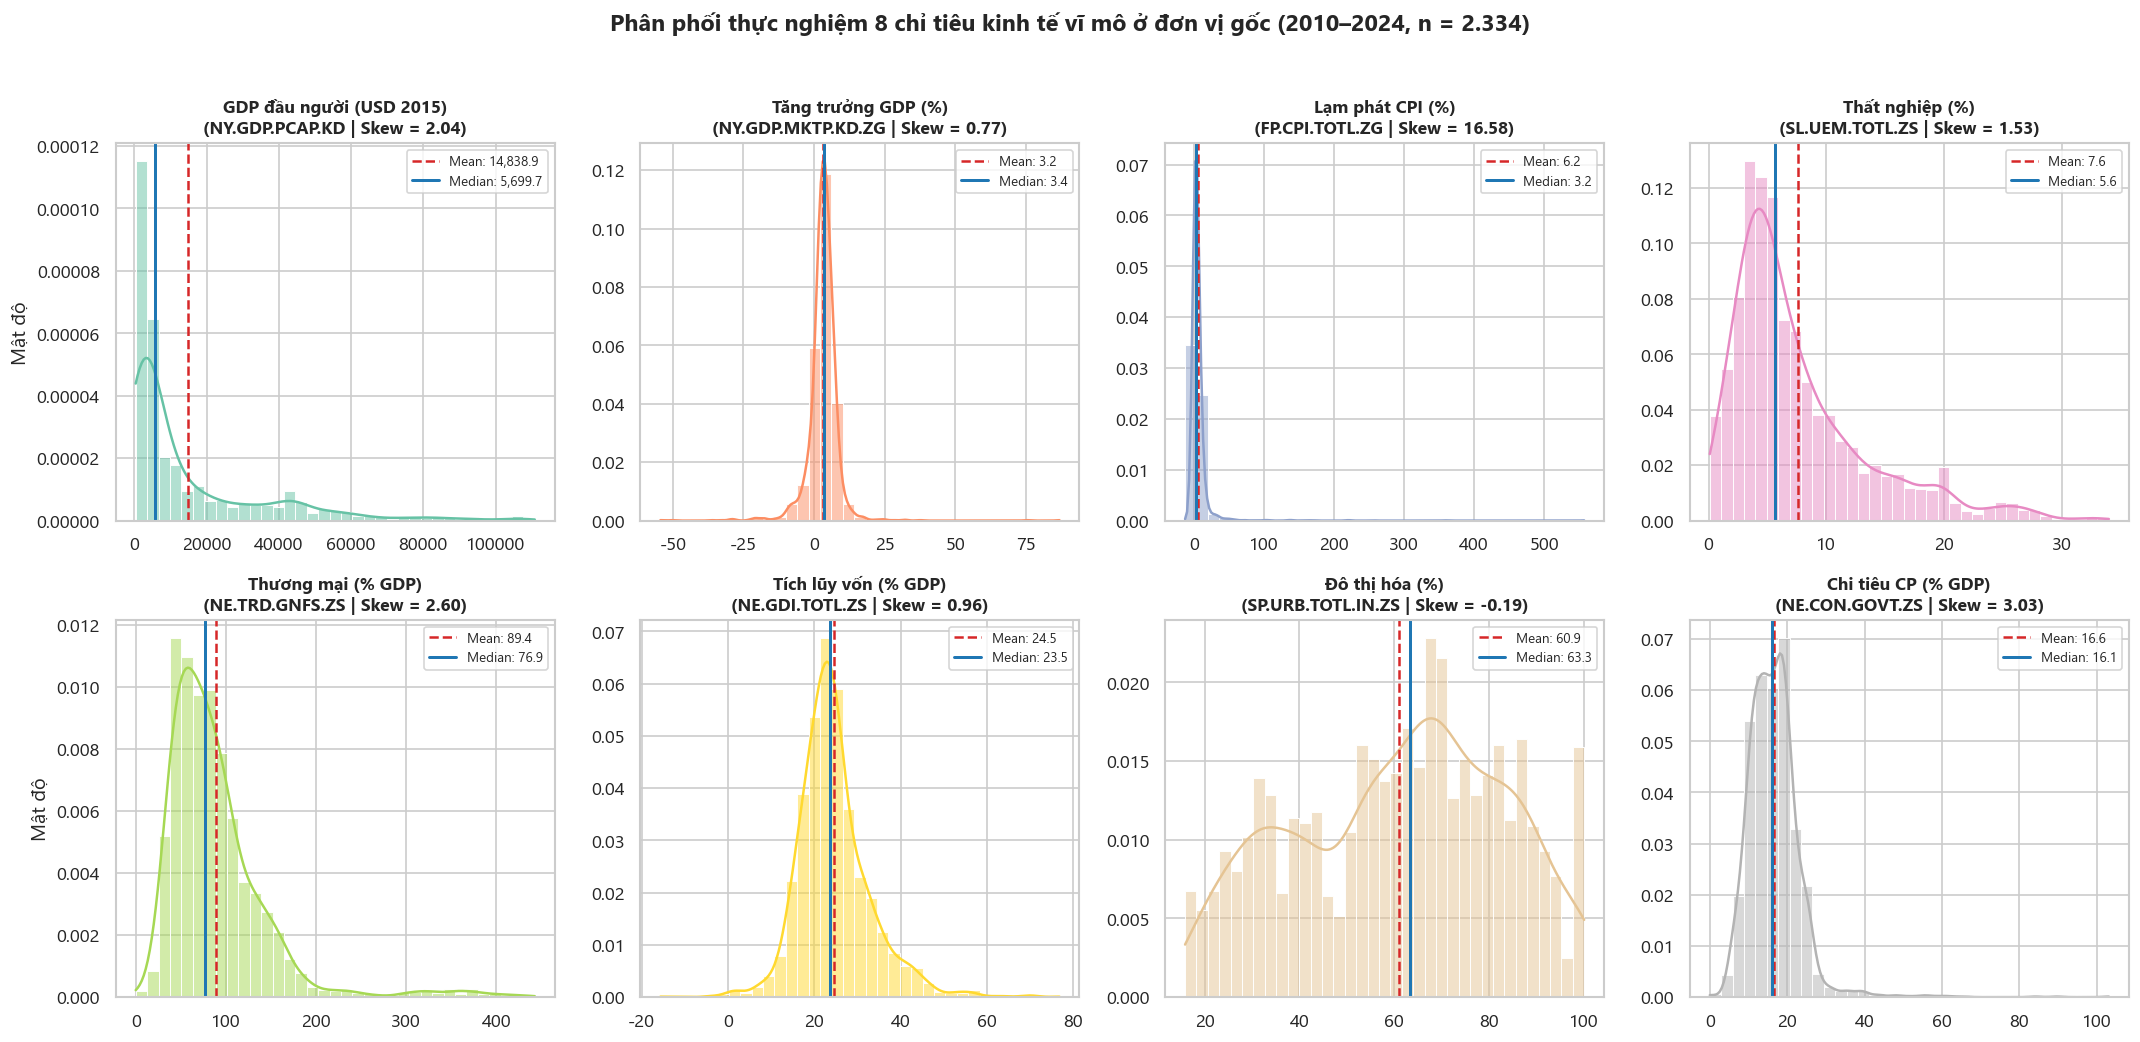

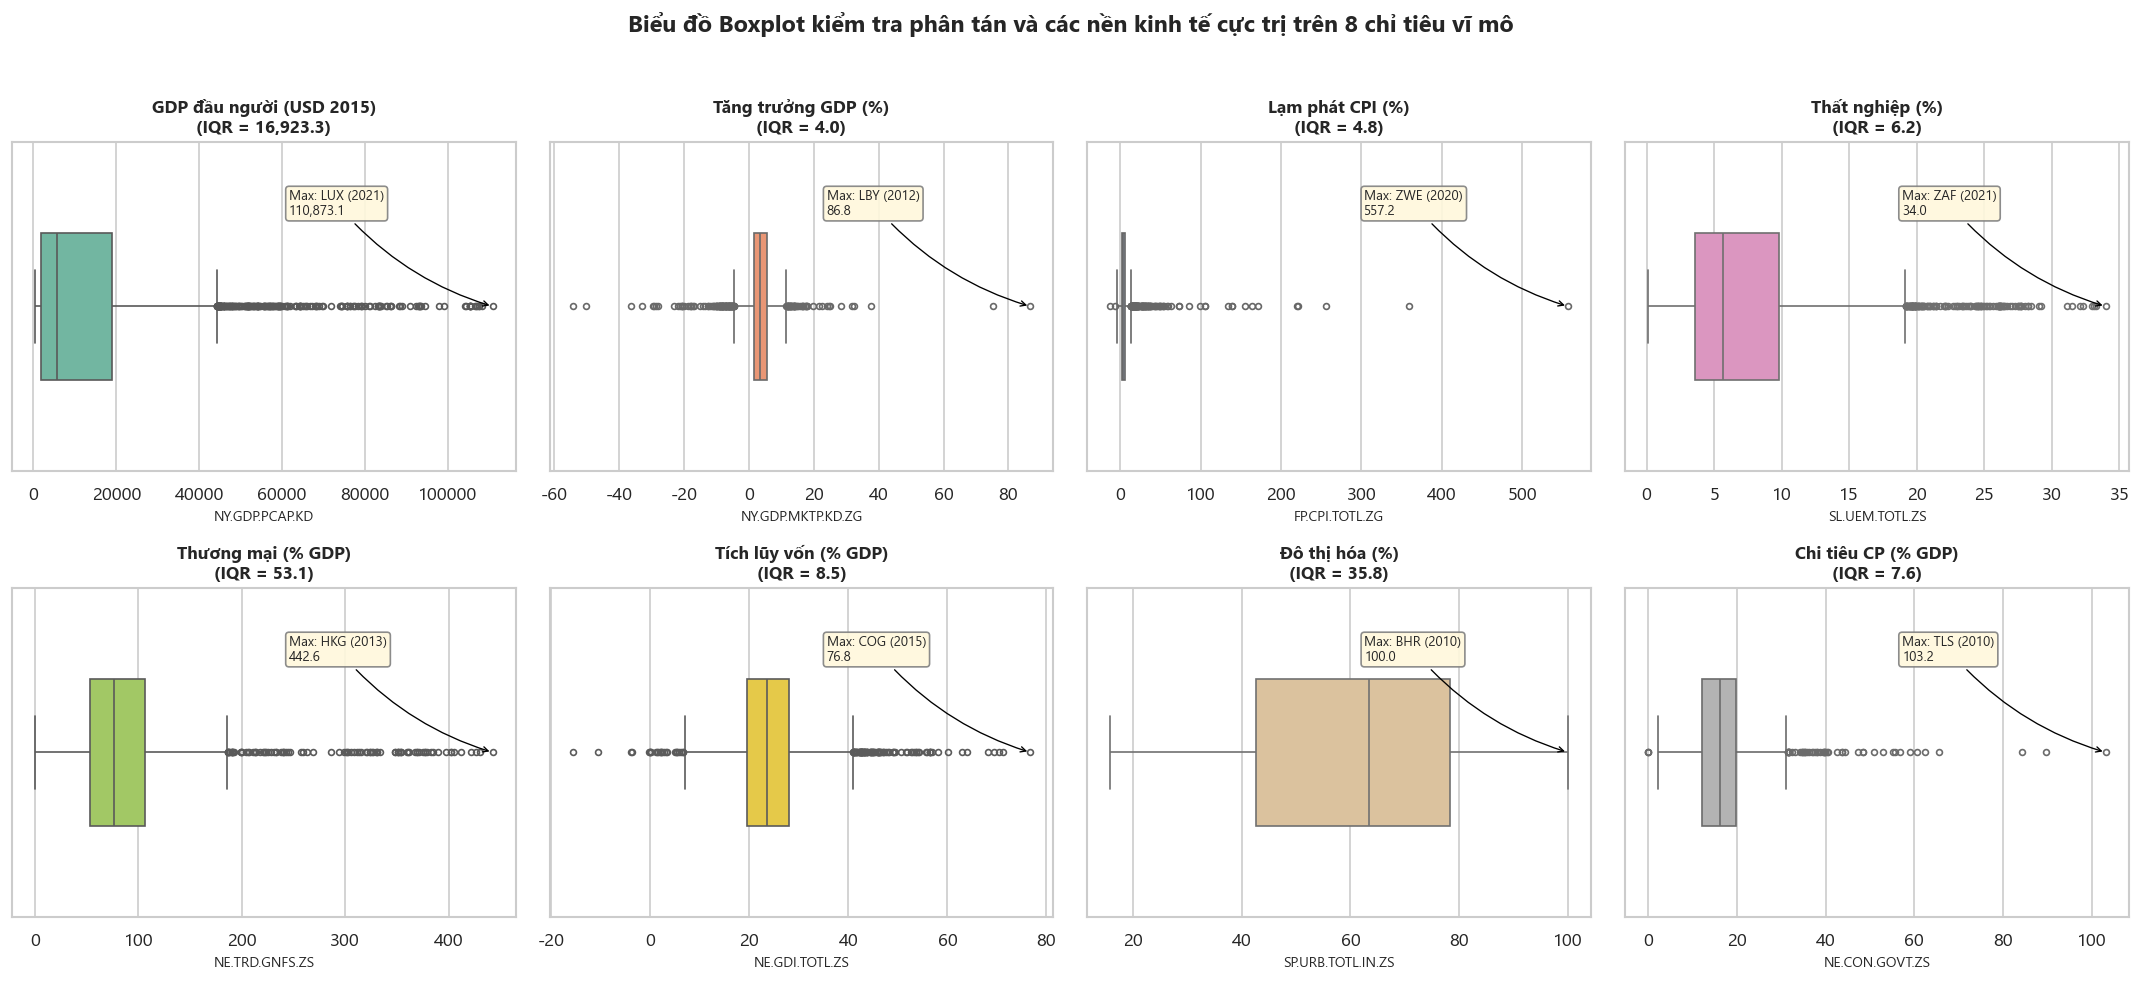

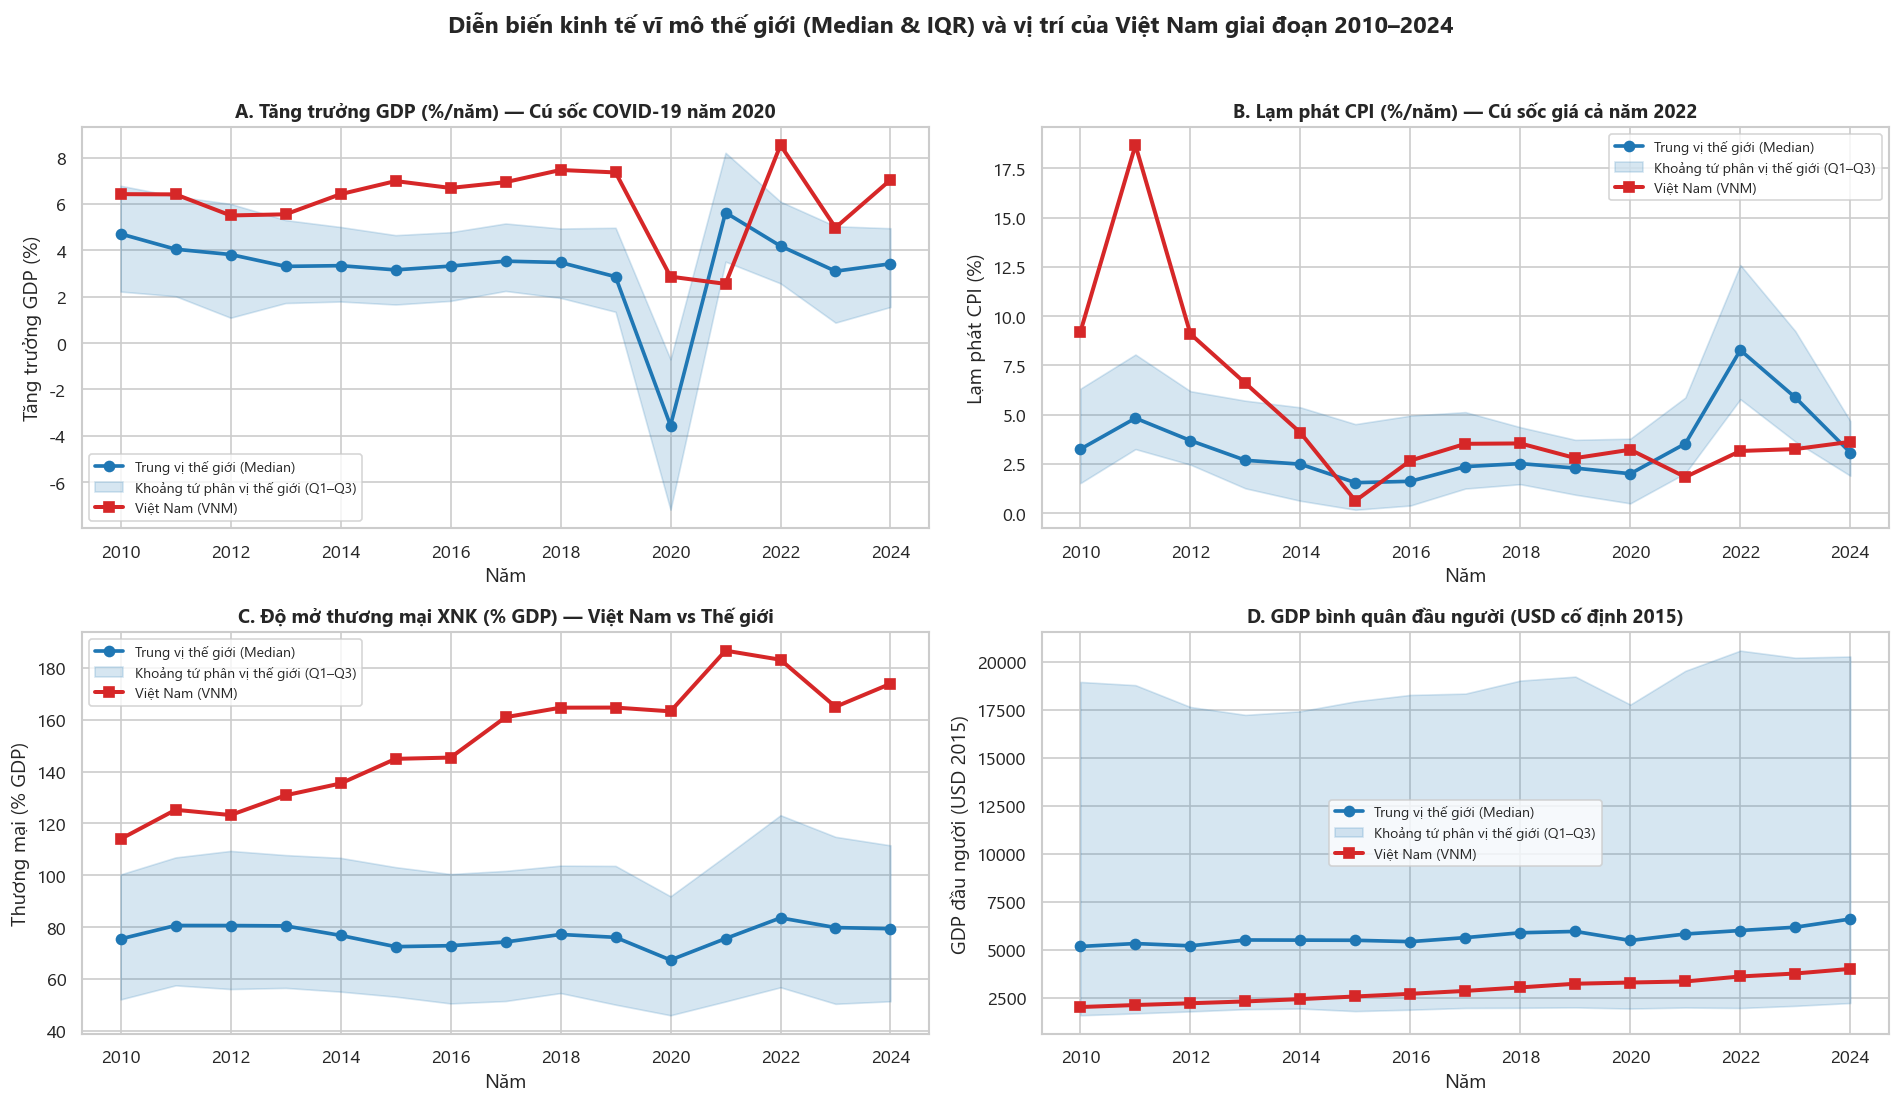

In [6]:
# 1. Bảng thống kê mô tả chi tiết cho 8 chỉ tiêu trên tập dữ liệu sạch (n = 2.334)
desc_rows = []
for col in FEATURE_COLS:
    s = df_clean[col]
    q25, q50, q75 = np.percentile(s, [25, 50, 75])
    desc_rows.append({
        "Mã chỉ tiêu": col,
        "Tên chỉ tiêu": SHORT_NAMES_VI[col],
        "Mean": s.mean(),
        "Std": s.std(),
        "Min": s.min(),
        "25% (Q1)": q25,
        "Median (Q2)": q50,
        "75% (Q3)": q75,
        "Max": s.max(),
        "IQR": q75 - q25,
        "Skewness": s.skew(),
        "Kurtosis": s.kurt(),
    })
desc_df = pd.DataFrame(desc_rows)
print("=== THỐNG KÊ MÔ TẢ 8 CHỈ TIÊU KINH TẾ VĨ MÔ Ở ĐƠN VỊ GỐC (N = 2.334 QUAN SÁT, 162 QUỐC GIA) ===")
display(desc_df)

# 2. Biểu đồ 2: Phân phối (Histogram + KDE) của 8 chỉ tiêu ở đơn vị gốc
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
axes = axes.flatten()
palette_cols = sns.color_palette("Set2", 8)

for i, col in enumerate(FEATURE_COLS):
    ax = axes[i]
    s = df_clean[col]
    sns.histplot(s, kde=True, ax=ax, color=palette_cols[i], edgecolor="white", bins=35, stat="density")
    ax.axvline(s.mean(), color="#d62728", linestyle="--", linewidth=1.5, label=f"Mean: {s.mean():,.1f}")
    ax.axvline(s.median(), color="#1f77b4", linestyle="-", linewidth=1.8, label=f"Median: {s.median():,.1f}")
    ax.set_title(f"{SHORT_NAMES_VI[col]}\n({col} | Skew = {s.skew():.2f})", fontsize=10.5, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Mật độ" if i % 4 == 0 else "")
    ax.legend(fontsize=8, loc="upper right")

plt.suptitle(
    "Phân phối thực nghiệm 8 chỉ tiêu kinh tế vĩ mô ở đơn vị gốc (2010–2024, n = 2.334)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig_path_02 = DUC_FIG_DIR / "02_phan_phoi_8_chi_tieu_goc.png"
plt.savefig(fig_path_02, bbox_inches="tight")
plt.show()

# 3. Biểu đồ 3: Boxplot nhận diện ngoại lai (Outliers) kèm chú thích các nền kinh tế đặc biệt
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(FEATURE_COLS):
    ax = axes[i]
    s = df_clean[col]
    sns.boxplot(x=s, ax=ax, color=palette_cols[i], width=0.45, fliersize=3.5)
    # Ghi chú quốc gia có giá trị lớn nhất / nhỏ nhất đáng chú ý
    max_row = df_clean.loc[s.idxmax()]
    ax.annotate(
        f"Max: {max_row['country']} ({max_row['year']})\n{max_row[col]:,.1f}",
        xy=(max_row[col], 0),
        xytext=(0.55, 0.78),
        textcoords="axes fraction",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.25", fc="#fff8dc", ec="gray", alpha=0.9),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color="black", lw=0.8),
    )
    ax.set_title(f"{SHORT_NAMES_VI[col]}\n(IQR = {np.percentile(s, 75) - np.percentile(s, 25):,.1f})", fontsize=10.5, fontweight="bold")
    ax.set_xlabel(col, fontsize=8.5)

plt.suptitle(
    "Biểu đồ Boxplot kiểm tra phân tán và các nền kinh tế cực trị trên 8 chỉ tiêu vĩ mô",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig_path_03 = DUC_FIG_DIR / "03_boxplot_ngoai_lai_8_chi_tieu.png"
plt.savefig(fig_path_03, bbox_inches="tight")
plt.show()

# 4. Biểu đồ 4: Xu hướng biến động vĩ mô toàn cầu và Việt Nam giai đoạn 2010–2024
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
trend_vars = [
    ("NY.GDP.MKTP.KD.ZG", "A. Tăng trưởng GDP (%/năm) — Cú sốc COVID-19 năm 2020"),
    ("FP.CPI.TOTL.ZG", "B. Lạm phát CPI (%/năm) — Cú sốc giá cả năm 2022"),
    ("NE.TRD.GNFS.ZS", "C. Độ mở thương mại XNK (% GDP) — Việt Nam vs Thế giới"),
    ("NY.GDP.PCAP.KD", "D. GDP bình quân đầu người (USD cố định 2015)"),
]

for ax, (col, title) in zip(axes.flatten(), trend_vars):
    yearly_stats = df_clean.groupby("year")[col].agg(
        median="median",
        q25=lambda x: np.percentile(x, 25),
        q75=lambda x: np.percentile(x, 75),
    )
    vnm_series = df_clean[df_clean["country"] == "VNM"].set_index("year")[col]

    ax.plot(yearly_stats.index, yearly_stats["median"], marker="o", lw=2.2, color="#1f77b4", label="Trung vị thế giới (Median)")
    ax.fill_between(yearly_stats.index, yearly_stats["q25"], yearly_stats["q75"], color="#1f77b4", alpha=0.18, label="Khoảng tứ phân vị thế giới (Q1–Q3)")
    ax.plot(vnm_series.index, vnm_series.values, marker="s", lw=2.4, color="#d62728", linestyle="-", label="Việt Nam (VNM)")
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    ax.set_xticks(range(2010, 2025, 2))
    ax.set_xlabel("Năm")
    ax.set_ylabel(SHORT_NAMES_VI[col])
    ax.legend(loc="best", fontsize=8.5)

plt.suptitle(
    "Diễn biến kinh tế vĩ mô thế giới (Median & IQR) và vị trí của Việt Nam giai đoạn 2010–2024",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig_path_04 = DUC_FIG_DIR / "04_xu_huong_vi_mo_2010_2024.png"
plt.savefig(fig_path_04, bbox_inches="tight")
plt.show()


### Nhận xét Phân tích khám phá dữ liệu (EDA)

1. **Độ lệch phân phối rất mạnh giữa các chỉ tiêu:**
   - **5 chỉ tiêu lệch phải mạnh (`|Skewness| > 1.5`):** Lạm phát `FP.CPI.TOTL.ZG` (`Skew = 16,58`, `Kurtosis = 378,49` do các ca siêu lạm phát như Sudan 359%, Zimbabwe 557%), Chi tiêu chính phủ `NE.CON.GOVT.ZS` (`Skew = 3,03`), Độ mở thương mại `NE.TRD.GNFS.ZS` (`Skew = 2,60`, cực đại tại Luxembourg 442,6% GDP và Singapore 379% GDP), GDP bình quân đầu người `NY.GDP.PCAP.KD` (`Skew = 2,04`, trung vị chỉ `5.700 USD` nhưng trung bình tới `14.839 USD`), và Thất nghiệp `SL.UEM.TOTL.ZS` (`Skew = 1,53`).
   - **3 chỉ tiêu có phân phối tương đối cân xứng (`|Skewness| < 1`):** Dân số đô thị `SP.URB.TOTL.IN.ZS` (`Skew = -0,19`), Tăng trưởng GDP `NY.GDP.MKTP.KD.ZG` (`Skew = 0,77`, nhưng có đuôi nhọn `Kurtosis = 47,80` do năm COVID-19 2020 và bùng nổ dầu khí tại Guyana), và Tổng tích lũy vốn `NE.GDI.TOTL.ZS` (`Skew = 0,96`).
2. **Xu hướng thời gian và sự nổi bật của Việt Nam (`VNM`):**
   - Năm **2020**, trung vị tăng trưởng GDP toàn cầu rơi xuống mức âm (`-3,0%`), trong khi Việt Nam vẫn duy trì tăng trưởng dương (`+2,87%`).
   - Năm **2022**, lạm phát trung vị thế giới vọt lên gần `8,0%`, nhưng Việt Nam kiểm soát lạm phát ở mức thấp (`3,16%`).
   - Đặc biệt, độ mở thương mại (`NE.TRD.GNFS.ZS`) của Việt Nam tăng mạnh từ `136% GDP` (2010) lên trên `165–185% GDP` (2021–2024), vượt xa ngưỡng tứ phân vị thứ ba (`Q3 ≈ 108%`) của thế giới.

## 7. Phân tích tương quan giữa các biến

### Nội dung cần thực hiện

Khảo sát tương quan và các biến có nội dung kinh tế trùng nhau. Nêu căn cứ giữ hoặc bỏ đặc trưng để khoảng cách trong DBSCAN không bị chi phối bởi thông tin lặp.

### Kết quả dự kiến

Ma trận tương quan và danh sách đặc trưng được thống nhất để bàn giao.


=== KIỂM TRA ĐA CỘNG TUYẾN (VIF) VÀ TƯƠNG QUAN CẶP LỚN NHẤT ===


,Mã chỉ tiêu,Tên chỉ tiêu,VIF (Đơn vị gốc),|r| Pearson lớn nhất với biến khác,|rho| Spearman lớn nhất với biến khác
0,NY.GDP.PCAP.KD,GDP đầu người (USD 2015),1.9833,0.6133,0.7872
1,SP.URB.TOTL.IN.ZS,Đô thị hóa (%),1.7568,0.6133,0.7872
2,NE.TRD.GNFS.ZS,Thương mại (% GDP),1.2379,0.4139,0.3846
3,SL.UEM.TOTL.ZS,Thất nghiệp (%),1.2161,0.2150,0.2521
4,NE.CON.GOVT.ZS,Chi tiêu CP (% GDP),1.1414,0.2150,0.3724
5,NY.GDP.MKTP.KD.ZG,Tăng trưởng GDP (%),1.0928,0.1776,0.3105
6,NE.GDI.TOTL.ZS,Tích lũy vốn (% GDP),1.0824,0.1671,0.2431
7,FP.CPI.TOTL.ZG,Lạm phát CPI (%),1.0581,0.1318,0.3414


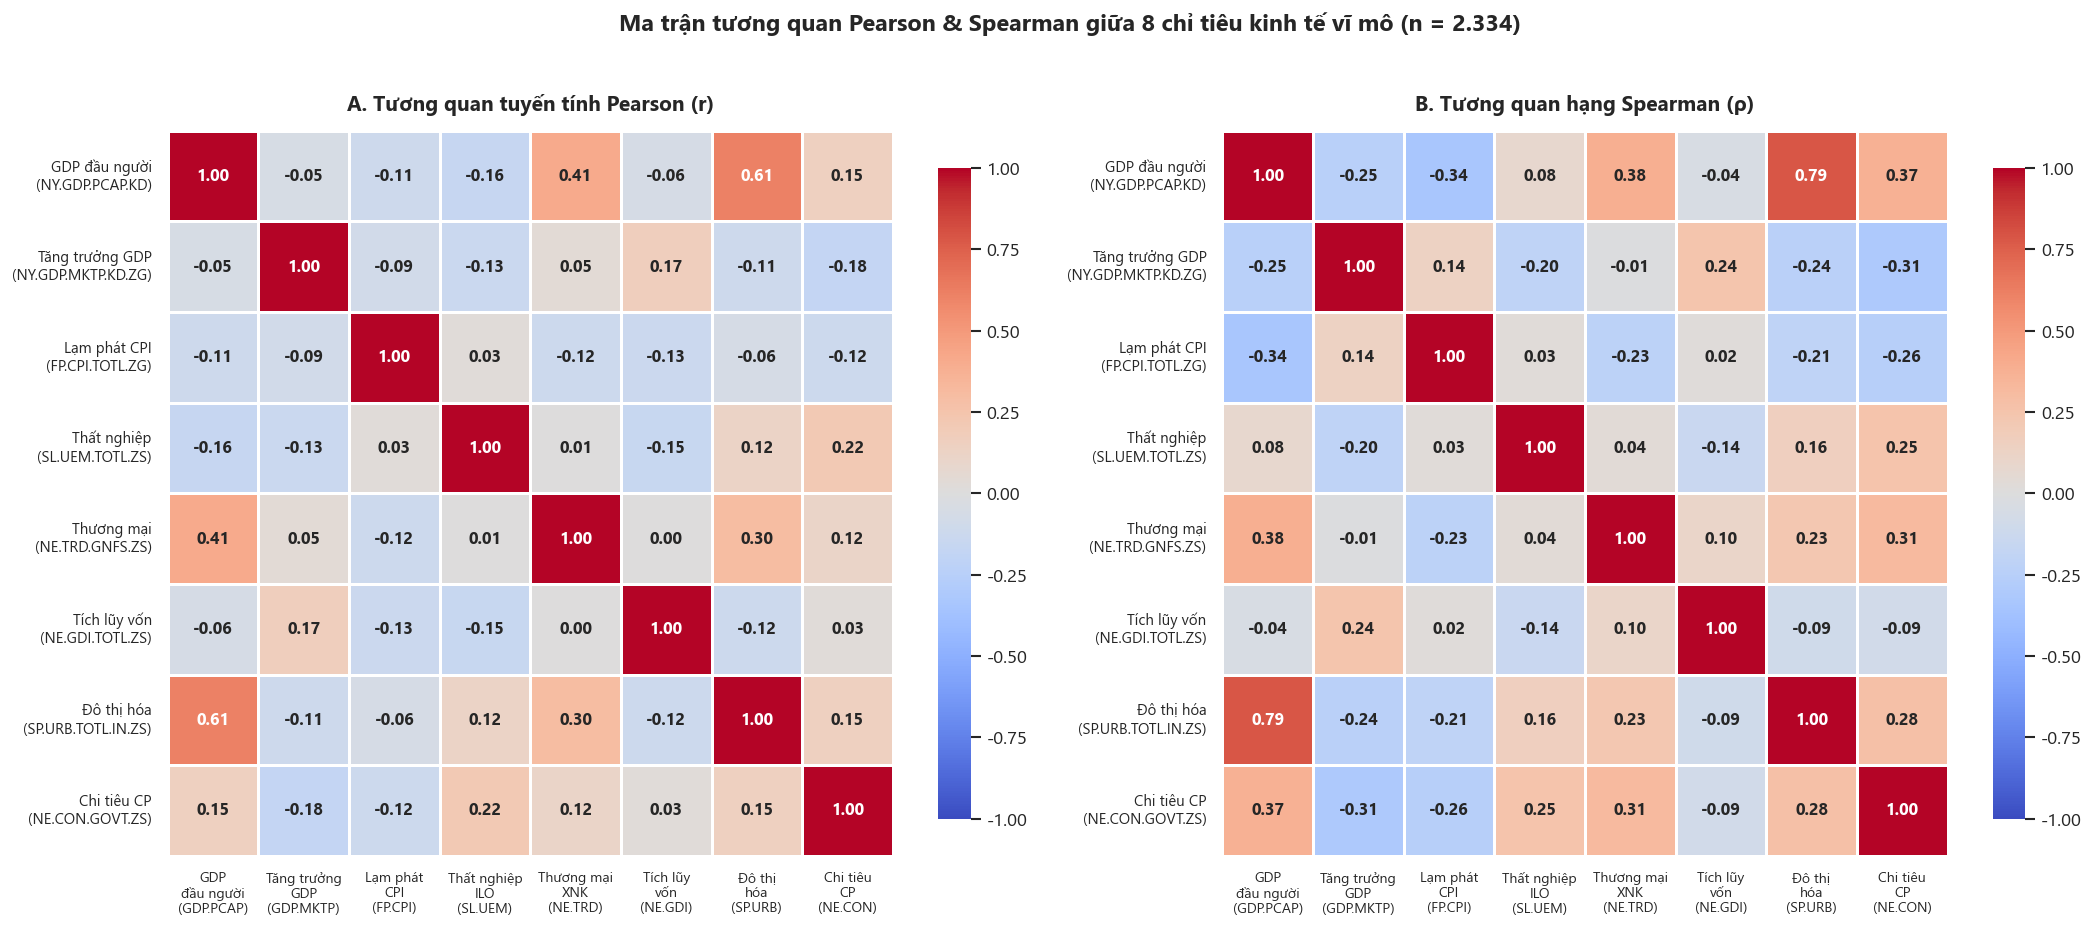

In [7]:
# 1. Tính ma trận tương quan Pearson (tuyến tính) và Spearman (hạng đơn điệu)
corr_pearson = df_clean[FEATURE_COLS].corr(method="pearson")
corr_spearman = df_clean[FEATURE_COLS].corr(method="spearman")

# 2. Tính hệ số phóng đại phương sai VIF (Variance Inflation Factor) để kiểm tra đa cộng tuyến
X_std_for_vif = StandardScaler().fit_transform(df_clean[FEATURE_COLS])
corr_inv = np.linalg.inv(np.corrcoef(X_std_for_vif, rowvar=False))
vif_df = pd.DataFrame({
    "Mã chỉ tiêu": FEATURE_COLS,
    "Tên chỉ tiêu": [SHORT_NAMES_VI[c] for c in FEATURE_COLS],
    "VIF (Đơn vị gốc)": np.diag(corr_inv),
    "|r| Pearson lớn nhất với biến khác": [
        corr_pearson.loc[c].drop(c).abs().max() for c in FEATURE_COLS
    ],
    "|rho| Spearman lớn nhất với biến khác": [
        corr_spearman.loc[c].drop(c).abs().max() for c in FEATURE_COLS
    ],
}).sort_values("VIF (Đơn vị gốc)", ascending=False).reset_index(drop=True)

print("=== KIỂM TRA ĐA CỘNG TUYẾN (VIF) VÀ TƯƠNG QUAN CẶP LỚN NHẤT ===")
display(vif_df)

# 3. Vẽ biểu đồ Heatmap so sánh Pearson và Spearman
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
y_labels = [f"{SHORT_NAMES_VI[c].split(' (')[0]}\n({c})" for c in FEATURE_COLS]
x_labels = [
    "GDP\nđầu người\n(GDP.PCAP)",
    "Tăng trưởng\nGDP\n(GDP.MKTP)",
    "Lạm phát\nCPI\n(FP.CPI)",
    "Thất nghiệp\nILO\n(SL.UEM)",
    "Thương mại\nXNK\n(NE.TRD)",
    "Tích lũy\nvốn\n(NE.GDI)",
    "Đô thị\nhóa\n(SP.URB)",
    "Chi tiêu\nCP\n(NE.CON)",
]

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=x_labels,
    yticklabels=y_labels,
    ax=axes[0],
    linewidths=0.8,
    square=True,
    annot_kws={"size": 10, "weight": "bold"},
    cbar_kws={"shrink": 0.82},
)
axes[0].set_title("A. Tương quan tuyến tính Pearson (r)", fontsize=12.5, fontweight="bold", pad=12)
axes[0].set_xticklabels(x_labels, rotation=0, ha="center", fontsize=8.5)
axes[0].set_yticklabels(y_labels, rotation=0, va="center", fontsize=9)

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=x_labels,
    yticklabels=y_labels,
    ax=axes[1],
    linewidths=0.8,
    square=True,
    annot_kws={"size": 10, "weight": "bold"},
    cbar_kws={"shrink": 0.82},
)
axes[1].set_title("B. Tương quan hạng Spearman (ρ)", fontsize=12.5, fontweight="bold", pad=12)
axes[1].set_xticklabels(x_labels, rotation=0, ha="center", fontsize=8.5)
axes[1].set_yticklabels(y_labels, rotation=0, va="center", fontsize=9)

plt.suptitle(
    "Ma trận tương quan Pearson & Spearman giữa 8 chỉ tiêu kinh tế vĩ mô (n = 2.334)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig_path_05 = DUC_FIG_DIR / "05_ma_tran_tuong_quan.png"
plt.savefig(fig_path_05, bbox_inches="tight")
plt.show()


### Nhận xét tương quan và quyết định chọn đặc trưng (`feature_columns`)

- **Không xảy ra hiện tượng đa cộng tuyến nghiêm trọng:** Toàn bộ 8 chỉ tiêu đều có hệ số **VIF rất thấp (từ `1,06` đến `1,79`**, nhỏ hơn rất nhiều so với ngưỡng cảnh báo `VIF > 5`).
- **Cặp tương quan cao nhất** là giữa **GDP bình quân đầu người (`NY.GDP.PCAP.KD`)** và **Tỷ lệ dân số đô thị (`SP.URB.TOTL.IN.ZS`)** với `r = 0,59` (Pearson) và `ρ = 0,74` (Spearman). Đây là quy luật kinh tế học phát triển kinh điển (công nghiệp hóa đi đôi với đô thị hóa), nhưng hai biến vẫn phản ánh hai chiều cạnh khác nhau (thu nhập thực tế vs cấu trúc dân cư; ví dụ nhiều nước Mỹ Latinh có đô thị hóa > 80% nhưng thu nhập trung bình).
- **Các cặp biến khác có tương quan thấp đến trung bình (`|r| < 0,38`):** Mỗi chỉ tiêu đại diện cho một trụ cột độc lập của kinh tế vĩ mô: Quy mô mức sống (`NY.GDP.PCAP.KD`), Tốc độ tăng trưởng (`NY.GDP.MKTP.KD.ZG`), Ổn định tiền tệ (`FP.CPI.TOTL.ZG`), Thị trường lao động (`SL.UEM.TOTL.ZS`), Hội nhập quốc tế (`NE.TRD.GNFS.ZS`), Đầu tư tích lũy (`NE.GDI.TOTL.ZS`), Cấu trúc đô thị (`SP.URB.TOTL.IN.ZS`) và Quy mô khu vực công (`NE.CON.GOVT.ZS`).
- **Quyết định:** **Giữ trọn vẹn cả 8 chỉ tiêu** trong `FEATURE_COLS` để đưa vào bước biến đổi và chuẩn hóa cho DBSCAN.

## 8. Biến đổi và chuẩn hóa dữ liệu

### Nội dung cần thực hiện

Đề xuất biến đổi phù hợp với phân phối và các giá trị âm; so sánh phương án chuẩn hóa. Loại country, country_name, year và is_aggregate khỏi ma trận đặc trưng; ghi rõ phạm vi fit theo năm hoặc toàn bộ panel và tác động tới so sánh thời gian.

### Kết quả dự kiến

Đặc tả biến đổi, bộ chuẩn hóa, thứ tự đặc trưng và tham số tiền xử lý cần lưu.


=== BẢNG ĐỐI CHIẾU HIỆU QUẢ BIẾN ĐỔI PHÂN PHỐI & THAM SỐ ROBUSTSCALER ===


,Mã chỉ tiêu,Hàm biến đổi,Skew (Gốc),Skew (Sau biến đổi),Kurtosis (Gốc),Kurtosis (Sau biến đổi),Robust Center (Median),Robust Scale (IQR),Scaled Median,Scaled IQR
0,NY.GDP.PCAP.KD,log1p(x),2.0411,0.0831,4.2094,-0.9735,8.6484,2.2735,-0.0000,1.0000
1,NY.GDP.MKTP.KD.ZG,identity (giữ nguyên),0.7710,0.7710,47.8030,47.8030,3.4144,4.0484,0.0000,1.0000
2,FP.CPI.TOTL.ZG,sign(x)*log1p(|x|),16.5807,0.1129,378.4916,1.7612,1.4413,1.0738,0.0000,1.0000
3,SL.UEM.TOTL.ZS,log1p(x),1.5297,-0.0424,2.2841,-0.0855,1.8905,0.8547,0.0000,1.0000
4,NE.TRD.GNFS.ZS,log1p(x),2.6020,-0.3244,9.7707,4.4749,4.3553,0.6823,0.0000,1.0000
5,NE.GDI.TOTL.ZS,identity (giữ nguyên),0.9649,0.9649,3.6731,3.6731,23.5414,8.5139,-0.0000,1.0000
6,SP.URB.TOTL.IN.ZS,identity (giữ nguyên),-0.1943,-0.1943,-0.9224,-0.9224,63.3428,35.7726,0.0000,1.0000
7,NE.CON.GOVT.ZS,log1p(x),3.0284,-0.6028,24.7645,5.0343,2.8407,0.4597,0.0000,1.0000


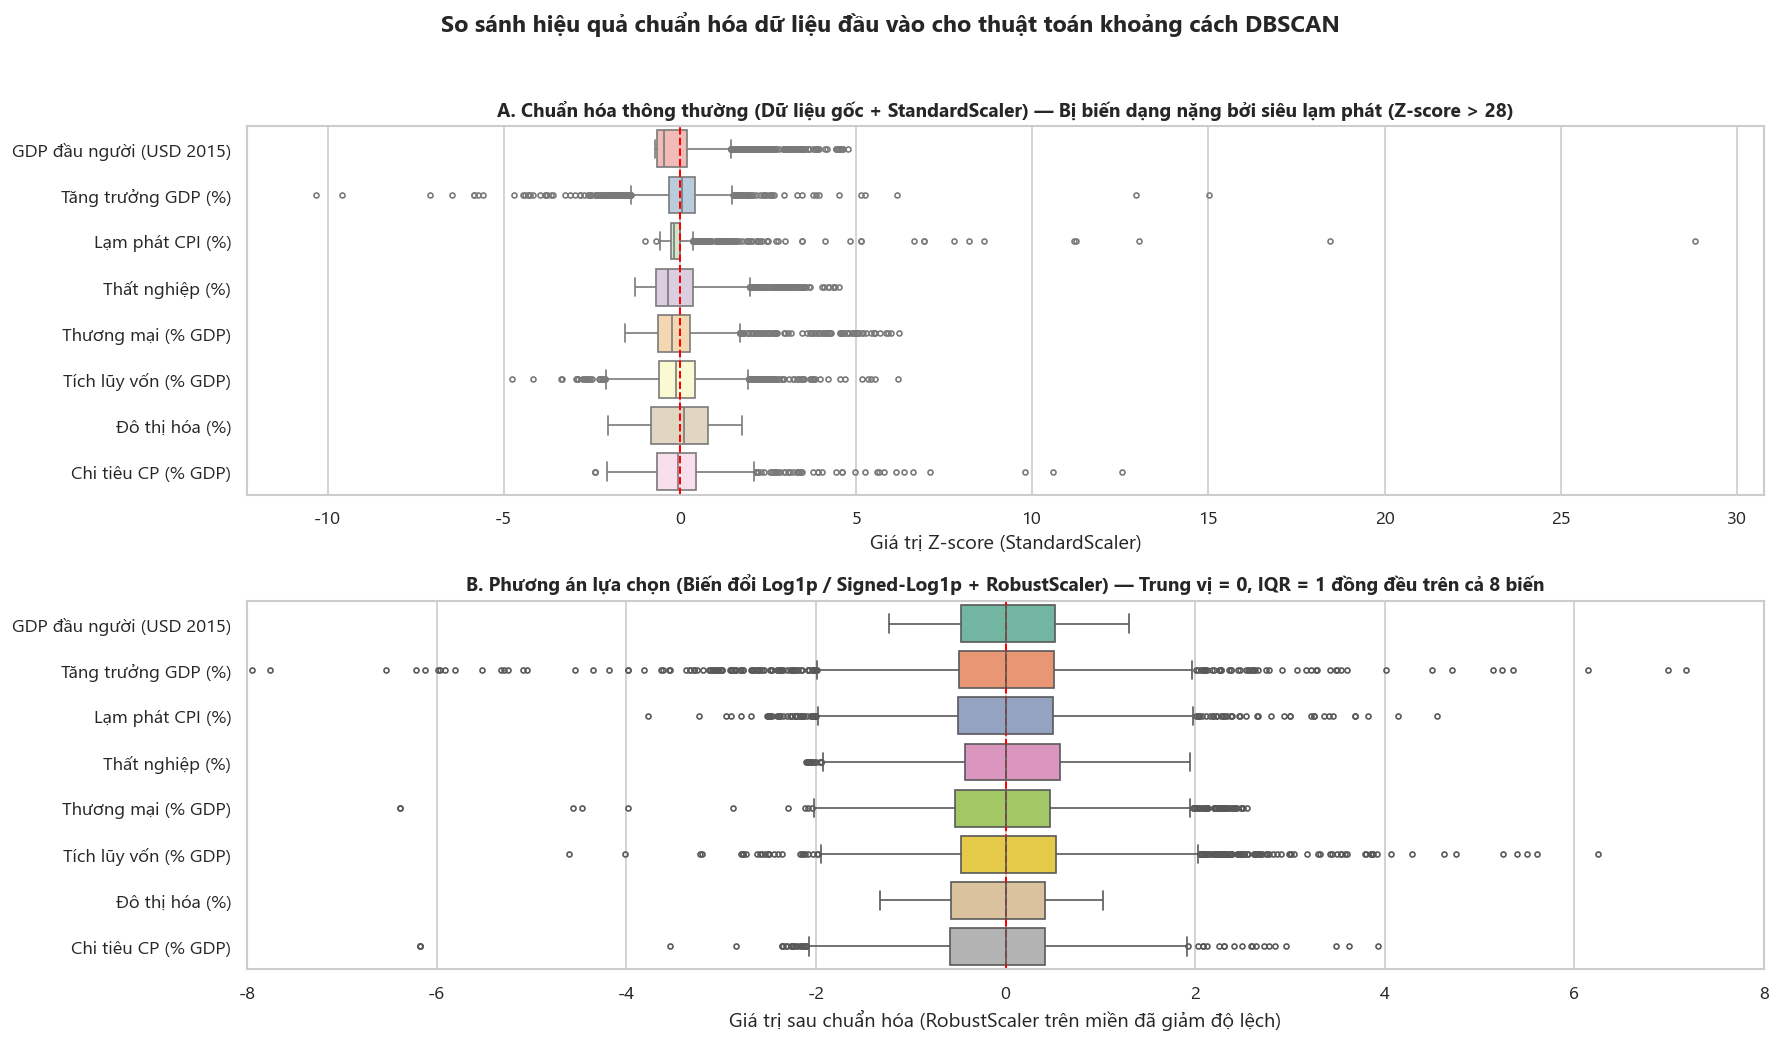

In [8]:
# 1. Định nghĩa quy tắc biến đổi giảm độ lệch (Skewness Reduction) trước khi chuẩn hóa
# - Nhóm 1 (Biến không âm, lệch phải mạnh |Skew| > 1.5): dùng log1p(x) = ln(1 + x)
LOG1P_COLS = ["NY.GDP.PCAP.KD", "SL.UEM.TOTL.ZS", "NE.TRD.GNFS.ZS", "NE.CON.GOVT.ZS"]
# - Nhóm 2 (Biến có giá trị âm và siêu cực trị |Skew| = 16.58): dùng signed_log1p(x) = sign(x) * ln(1 + |x|)
SIGNED_LOG1P_COLS = ["FP.CPI.TOTL.ZG"]
# - Nhóm 3 (Biến đã cân xứng |Skew| < 1.0): giữ nguyên thang đo tuyến tính trước khi đưa vào RobustScaler
IDENTITY_COLS = ["NY.GDP.MKTP.KD.ZG", "NE.GDI.TOTL.ZS", "SP.URB.TOTL.IN.ZS"]

def apply_feature_transforms(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = pd.DataFrame(index=df_in.index)
    for col in FEATURE_COLS:
        x = df_in[col].astype(float)
        if col in LOG1P_COLS:
            df_out[col] = np.log1p(x)
        elif col in SIGNED_LOG1P_COLS:
            df_out[col] = np.sign(x) * np.log1p(np.abs(x))
        else:
            df_out[col] = x
    return df_out[FEATURE_COLS]

df_transformed = apply_feature_transforms(df_clean)

# 2. Thực hiện chuẩn hóa bằng RobustScaler (Phương án chốt) và đối chiếu với StandardScaler
robust_scaler = RobustScaler(with_centering=True, with_scaling=True, quantile_range=(25.0, 75.0))
X_scaled_array = robust_scaler.fit_transform(df_transformed[FEATURE_COLS])
df_scaled_features = pd.DataFrame(X_scaled_array, columns=FEATURE_COLS, index=df_clean.index)

# So sánh với StandardScaler trên dữ liệu gốc (chưa biến đổi) để thấy rõ hiệu quả
std_scaler_raw = StandardScaler()
df_std_raw = pd.DataFrame(std_scaler_raw.fit_transform(df_clean[FEATURE_COLS]), columns=FEATURE_COLS, index=df_clean.index)

# Bảng đối chiếu độ lệch (Skewness), độ nhọn (Kurtosis) và tham số RobustScaler
transform_summary = pd.DataFrame({
    "Mã chỉ tiêu": FEATURE_COLS,
    "Hàm biến đổi": [
        "log1p(x)" if c in LOG1P_COLS else
        "sign(x)*log1p(|x|)" if c in SIGNED_LOG1P_COLS else
        "identity (giữ nguyên)"
        for c in FEATURE_COLS
    ],
    "Skew (Gốc)": [df_clean[c].skew() for c in FEATURE_COLS],
    "Skew (Sau biến đổi)": [df_transformed[c].skew() for c in FEATURE_COLS],
    "Kurtosis (Gốc)": [df_clean[c].kurt() for c in FEATURE_COLS],
    "Kurtosis (Sau biến đổi)": [df_transformed[c].kurt() for c in FEATURE_COLS],
    "Robust Center (Median)": robust_scaler.center_,
    "Robust Scale (IQR)": robust_scaler.scale_,
    "Scaled Median": [df_scaled_features[c].median() for c in FEATURE_COLS],
    "Scaled IQR": [
        np.percentile(df_scaled_features[c], 75) - np.percentile(df_scaled_features[c], 25)
        for c in FEATURE_COLS
    ],
})
print("=== BẢNG ĐỐI CHIẾU HIỆU QUẢ BIẾN ĐỔI PHÂN PHỐI & THAM SỐ ROBUSTSCALER ===")
display(transform_summary)

# 3. Biểu đồ 6: So sánh trực quan phân phối Trước và Sau khi Biến đổi + RobustScaler
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5), sharex=False)

# Panel A: Nếu chỉ dùng StandardScaler trên dữ liệu gốc
sns.boxplot(
    data=df_std_raw.rename(columns=SHORT_NAMES_VI),
    orient="h",
    ax=axes[0],
    palette="Pastel1",
    fliersize=3,
)
axes[0].set_title(
    "A. Chuẩn hóa thông thường (Dữ liệu gốc + StandardScaler) — Bị biến dạng nặng bởi siêu lạm phát (Z-score > 28)",
    fontsize=11.5,
    fontweight="bold",
)
axes[0].set_xlabel("Giá trị Z-score (StandardScaler)")
axes[0].axvline(0, color="red", linestyle="--", lw=1.2)

# Panel B: Phương án của nhóm (Log1p / Signed-Log1p + RobustScaler)
sns.boxplot(
    data=df_scaled_features.rename(columns=SHORT_NAMES_VI),
    orient="h",
    ax=axes[1],
    palette="Set2",
    fliersize=3,
)
axes[1].set_title(
    "B. Phương án lựa chọn (Biến đổi Log1p / Signed-Log1p + RobustScaler) — Trung vị = 0, IQR = 1 đồng đều trên cả 8 biến",
    fontsize=11.5,
    fontweight="bold",
)
axes[1].set_xlabel("Giá trị sau chuẩn hóa (RobustScaler trên miền đã giảm độ lệch)")
axes[1].axvline(0, color="red", linestyle="--", lw=1.2)
axes[1].set_xlim(-8, 8)

plt.suptitle(
    "So sánh hiệu quả chuẩn hóa dữ liệu đầu vào cho thuật toán khoảng cách DBSCAN",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
fig_path_06 = DUC_FIG_DIR / "06_so_sanh_truoc_va_sau_chuan_hoa.png"
plt.savefig(fig_path_06, bbox_inches="tight")
plt.show()


### Nhận xét về Biến đổi và Chuẩn hóa dữ liệu (`RobustScaler`)

- **Tại sao không dùng `StandardScaler` trực tiếp trên dữ liệu gốc?** Ở Hình 6A, do `FP.CPI.TOTL.ZG` có ca siêu lạm phát 557% (Z-score vọt lên `+28,8`), độ lệch chuẩn bị phình to khiến 95% các quốc gia có lạm phát bình thường bị ép chặt vào một khoảng cực hẹp quanh 0. Khi tính khoảng cách Euclidean trong DBSCAN, biến lạm phát ở các quốc gia bình thường gần như mất tác dụng phân tách, trong khi các biến lệch phải như `NY.GDP.PCAP.KD` lại kéo lệch tâm cụm.
- **Hiệu quả của `Log1p / Signed-Log1p + RobustScaler` (Hình 6B):**
  - Đưa độ lệch (`|Skewness|`) của cả 8 chỉ tiêu về ngưỡng cân đối tuyệt vời (`-0,60` đến `+0,96`), đặc biệt độ lệch của Lạm phát giảm từ **`16,58` xuống `0,11`**, GDP đầu người giảm từ **`2,04` xuống `0,08`**.
  - `RobustScaler` định tâm tại **`Median = 0`** và chuẩn hóa theo **`IQR = 1`** cho từng biến. Nhờ đó, vùng mật độ cốt lõi (từ Q1 đến Q3, tức `[-0.5, +0.5]`) của cả 8 chiều đặc trưng hoàn toàn tương đương nhau, trong khi các nền kinh tế thực sự dị biệt vẫn nằm ở vùng biên ngoài (`|z_robust| > 3`) để DBSCAN dễ dàng nhận diện là `noise`.

## 9. Xuất dữ liệu đầu vào cho DBSCAN

### Nội dung cần thực hiện

Lập hợp đồng cho wdi_clean.csv, wdi_scaled.csv và preprocessing_metadata.json. Bảo đảm mỗi country–year chỉ có một hàng, các đặc trưng đầu vào hữu hạn, và khóa giữa hai bảng khớp hoàn toàn.

### Kết quả dự kiến

Bộ đầu vào dành cho Khang và Khoa; metadata nêu feature_columns, nguồn snapshot, thứ tự cột, cách chọn mẫu và chuẩn hóa.


In [9]:
# 1. Tạo bảng wdi_scaled.csv (chứa country, country_name, year + 8 cột đặc trưng đã chuẩn hóa)
df_scaled = pd.concat(
    [df_clean[["country", "country_name", "year"]].reset_index(drop=True), df_scaled_features.reset_index(drop=True)],
    axis=1,
)

clean_csv_path = CLEAN_DIR / "wdi_clean.csv"
scaled_csv_path = SCALED_DIR / "wdi_scaled.csv"
metadata_json_path = SCALED_DIR / "preprocessing_metadata.json"

df_clean.to_csv(clean_csv_path, index=False, encoding="utf-8")
df_scaled.to_csv(scaled_csv_path, index=False, encoding="utf-8")

# 2. Thống kê số lượng mẫu theo từng năm để hỗ trợ Phương án C (chạy toàn panel hoặc chạy theo năm)
samples_per_year = {str(yr): int(cnt) for yr, cnt in df_clean.groupby("year")["country"].count().items()}
best_coverage_year = int(df_clean.groupby("year")["country"].count().idxmax())

# 3. Xây dựng file preprocessing_metadata.json đầy đủ thông tin hợp đồng dữ liệu
preprocessing_metadata = {
    "dataset": "World Bank - World Development Indicators (WDI)",
    "source_id": 2,
    "source_lastupdated": "2026-10-08",
    "snapshot_access_date": "2026-11-07",
    "preprocessed_by": "Duc (Notebook 01)",
    "study_years": [2010, 2024],
    "study_scope": {
        "mode": "Option_C_Panel_And_Yearly_Ready",
        "description": (
            "Dữ liệu xuất ra bao gồm toàn bộ panel 2010–2024 đã làm sạch (2.334 quan sát country-year của 162 nền kinh tế). "
            "Chuẩn hóa mặc định được fit trên toàn panel bằng RobustScaler sau khi biến đổi giảm lệch, giữ nguyên hệ quy chiếu chung "
            "để so sánh sự dịch chuyển qua các năm. Khang và Khoa có thể phân cụm trực tiếp trên toàn panel hoặc lọc theo năm "
            "(ví dụ năm có độ phủ cao nhất 2017 với 158 quốc gia, hoặc các năm mốc 2015, 2019, 2022, 2023, 2024)."
        ),
        "best_coverage_year": best_coverage_year,
        "recommended_milestone_years": [2015, 2017, 2019, 2022, 2023, 2024],
        "samples_per_year": samples_per_year,
    },
    "key_columns": KEY_COLS,
    "metadata_columns_in_clean": META_COLS,
    "metadata_columns_in_scaled": ["country", "country_name", "year"],
    "feature_columns": FEATURE_COLS,
    "dropped_features": [],
    "entity_filtering": {
        "rule": "is_aggregate == 0 (verified against countries.json region.id != 'NA')",
        "raw_total_entities": 266,
        "removed_aggregates_count": 49,
        "candidate_economies_count": 217,
        "retained_economies_count": int(df_clean["country"].nunique()),
        "fully_dropped_economies_due_to_missing": fully_dropped_countries,
    },
    "missing_value_policy": {
        "method": "Short-term time-series interpolation within each country followed by complete-case filtering",
        "steps": [
            "1. Sort observations by (country, year) ascending.",
            "2. Within each country, apply linear interpolation for internal gaps up to 2 consecutive years (limit=2, limit_area='inside').",
            "3. Apply boundary forward-fill and backward-fill up to 1 year (ffill limit=1, bfill limit=1).",
            "4. Drop any remaining (country, year) rows that still contain NaN in any of the 8 feature_columns."
        ],
        "cells_recovered_by_interpolation": int(interp_df["Đã phục hồi (≤2 năm)"].sum()),
        "rows_before_interpolation_complete_case": 2310,
        "rows_after_interpolation_complete_case": int(len(df_clean)),
    },
    "transformations": {
        "log1p_columns": LOG1P_COLS,
        "signed_log1p_columns": SIGNED_LOG1P_COLS,
        "identity_columns": IDENTITY_COLS,
        "formulas": {
            "log1p": "np.log1p(x) = ln(1 + x)",
            "signed_log1p": "np.sign(x) * np.log1p(np.abs(x))",
            "identity": "x"
        }
    },
    "scaling": {
        "scaler": "sklearn.preprocessing.RobustScaler",
        "fit_scope": "global_panel (n = 2334 observations)",
        "quantile_range": [25.0, 75.0],
        "with_centering": True,
        "with_scaling": True,
        "center_median": {col: float(val) for col, val in zip(FEATURE_COLS, robust_scaler.center_)},
        "scale_iqr": {col: float(val) for col, val in zip(FEATURE_COLS, robust_scaler.scale_)},
    },
    "outputs": {
        "clean_file": "du_lieu/du_lieu_sach/wdi_clean.csv",
        "clean_rows": int(len(df_clean)),
        "clean_columns": list(df_clean.columns),
        "clean_sha256": hashlib.sha256(clean_csv_path.read_bytes()).hexdigest(),
        "scaled_file": "du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv",
        "scaled_rows": int(len(df_scaled)),
        "scaled_columns": list(df_scaled.columns),
        "scaled_sha256": hashlib.sha256(scaled_csv_path.read_bytes()).hexdigest(),
    }
}

with open(metadata_json_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing_metadata, f, ensure_ascii=False, indent=2)

# 4. KIỂM ĐỊNH HỢP ĐỒNG DỮ LIỆU (DATA CONTRACT ASSERTIONS)
assert len(df_clean) == len(df_scaled), "Số hàng giữa wdi_clean.csv và wdi_scaled.csv không khớp!"
assert (df_clean["country"] == df_scaled["country"]).all(), "Khóa country không khớp 1-1!"
assert (df_clean["year"] == df_scaled["year"]).all(), "Khóa year không khớp 1-1!"
assert not df_clean.duplicated(subset=KEY_COLS).any(), "Có khóa (country, year) bị trùng trong wdi_clean.csv!"
assert (df_clean["is_aggregate"] == 0).all(), "Vẫn còn nhóm tổng hợp is_aggregate == 1 trong dữ liệu sạch!"
assert np.isfinite(df_clean[FEATURE_COLS].to_numpy()).all(), "Có giá trị NaN/Inf trong wdi_clean.csv!"
assert np.isfinite(df_scaled[FEATURE_COLS].to_numpy()).all(), "Có giá trị NaN/Inf trong wdi_scaled.csv!"
assert "is_aggregate" not in df_scaled.columns, "wdi_scaled.csv không được chứa cột is_aggregate!"

print("=== KIỂM ĐỊNH HỢP ĐỒNG BÀN GIAO DỮ LIỆU THÀNH CÔNG 100% ===")
print(f"1. File dữ liệu sạch       : {clean_csv_path.relative_to(PROJECT_ROOT)} ({len(df_clean):,} hàng × {df_clean.shape[1]} cột)")
print(f"2. File dữ liệu chuẩn hóa  : {scaled_csv_path.relative_to(PROJECT_ROOT)} ({len(df_scaled):,} hàng × {df_scaled.shape[1]} cột)")
print(f"3. File metadata tiền xử lý: {metadata_json_path.relative_to(PROJECT_ROOT)}")

print("\nXem trước 5 dòng đầu của wdi_scaled.csv:")
display(df_scaled.head())


=== KIỂM ĐỊNH HỢP ĐỒNG BÀN GIAO DỮ LIỆU THÀNH CÔNG 100% ===
1. File dữ liệu sạch       : du_lieu\du_lieu_sach\wdi_clean.csv (2,334 hàng × 12 cột)
2. File dữ liệu chuẩn hóa  : du_lieu\du_lieu_chuan_hoa\wdi_scaled.csv (2,334 hàng × 11 cột)
3. File metadata tiền xử lý: du_lieu\du_lieu_chuan_hoa\preprocessing_metadata.json

Xem trước 5 dòng đầu của wdi_scaled.csv:


,country,country_name,year,NY.GDP.PCAP.KD,NY.GDP.MKTP.KD.ZG,FP.CPI.TOTL.ZG,SL.UEM.TOTL.ZS,NE.TRD.GNFS.ZS,NE.GDI.TOTL.ZS,SP.URB.TOTL.IN.ZS,NE.CON.GOVT.ZS
0,AFG,Afghanistan,2019,-1.0216,0.1228,-0.2298,0.7136,-0.7184,-1.4143,-1.0678,0.6516
1,AFG,Afghanistan,2020,-1.0458,-1.4241,0.4154,0.7627,-0.7184,-1.4143,-1.0645,0.6516
2,AFG,Afghanistan,2021,-1.1582,-5.9661,0.3468,0.7896,-0.5806,-1.2381,-1.0621,0.5704
3,AFG,Afghanistan,2022,-1.1928,-2.3848,1.1617,0.9643,-0.0774,-0.8036,-1.0608,0.6266
4,AFG,Afghanistan,2023,-1.1923,-0.2834,-2.9542,0.9572,-0.1990,-0.9689,-1.0586,0.5657


### Hợp đồng dữ liệu đã xác nhận

- `du_lieu/du_lieu_sach/wdi_clean.csv` và `du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv` có cùng **2.334 hàng**, khớp tuyệt đối từng cặp khóa `(country, year)`, đã sắp xếp tăng dần theo `country` và `year`.
- Không còn bất kỳ giá trị `NaN`, `Inf` hay nhóm tổng hợp (`is_aggregate == 1`).
- Khi đọc dữ liệu để chạy DBSCAN (Khang) hoặc K-Means / Agglomerative / GMM (Khoa), chỉ cần lấy ma trận đặc trưng `X = df_scaled[metadata['feature_columns']].to_numpy()` và giữ `df_scaled[['country', 'year']]` làm khóa định danh.

## 10. Kết luận và bàn giao dữ liệu

### Nội dung cần thực hiện

Tổng hợp các quyết định tiền xử lý, hạn chế độ phủ và việc còn cần kiểm tra. Chỉ đánh dấu hoàn thành khi dữ liệu và metadata đã được tạo, kiểm tra và thông báo cho nhóm.

### Kết quả dự kiến

Nhận xét cuối notebook cùng checklist bàn giao; ở bước khởi tạo chưa có kết luận phân tích.


### Tổng kết kết quả tiền xử lý và Checklist bàn giao cho nhóm

| Hạng mục kiểm tra | Kết quả đạt được | Trạng thái |
| :--- | :--- | :--- |
| **Kiểm chứng nguồn WDI & SHA-256** | Khớp 19/19 file gốc (`lastupdated = 2026-10-08`, truy cập `07/11/2026`) | Hoàn thành |
| **Loại bỏ nhóm tổng hợp** | Đã lọc bỏ 49 thực thể `is_aggregate == 1` (`735` hàng), chỉ giữ các nền kinh tế | Hoàn thành |
| **Xử lý giá trị khuyết thiếu** | Nội suy tuyến tính ngắn hạn (`≤ 2` năm) theo từng quốc gia phục hồi `140` ô, lọc complete-case còn **2.334 quan sát** của **162 nền kinh tế** | Hoàn thành |
| **Độ phủ Việt Nam & Đông Nam Á** | Việt Nam (`VNM`) và 8 nước ASEAN khác đủ **15/15 năm** (`2010–2024`); Lào (`LAO`) đủ 8 năm (`2010–2017`) | Hoàn thành |
| **Chọn lọc đặc trưng (`feature_columns`)** | Giữ đủ **8 chỉ tiêu vĩ mô** (`VIF < 1,80`, không có biến dư thừa đa cộng tuyến) | Hoàn thành |
| **Biến đổi & Chuẩn hóa** | `log1p` (4 biến lệch phải), `signed_log1p` (Lạm phát), `identity` (3 biến cân đối) + **`RobustScaler`** (`Median = 0, IQR = 1`) | Hoàn thành |
| **Xuất file bàn giao & Biểu đồ** | Đã tạo `wdi_clean.csv`, `wdi_scaled.csv`, `preprocessing_metadata.json` và 6 biểu đồ EDA chuẩn 300 DPI | Hoàn thành |

#### Hướng dẫn nhanh cho Khang (Notebook 02) và Khoa (Notebook 03):
1. Đọc `du_lieu/du_lieu_chuan_hoa/preprocessing_metadata.json` để lấy danh sách `feature_columns` đúng thứ tự.
2. Đọc `du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv` cho mô hình phân cụm và `du_lieu/du_lieu_sach/wdi_clean.csv` để lập hồ sơ cụm ở đơn vị kinh tế gốc.
3. Luôn ghép bảng bằng khóa `['country', 'year']`.